In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [2]:
assets = [
    "Email Server",
    "Customer Database",
    "Payment Gateway",
    "Employee Records",
    "Medical Records",
    "Research Database",
    "Cloud Storage",
    "VPN Server",
    "Certificate Authority",
    "Financial Ledger",
    "IoT Network",
    "Identity Management",
    "Payroll System",
    "Backup Server",
    "Government Records"
]

In [3]:
np.random.seed(42)
data = {
    "Asset": assets,
    "Sensitivity":np.random.randint(1,6,len(assets)),
    "Confidentiality_Lifetime":np.random.randint(1,6,len(assets)),
    "Future_Quantum_Risk":np.random.randint(1,6,len(assets)),
    "Infrastructure_Readiness":np.random.randint(1,6,len(assets)),
    "Migration_Cost":np.random.randint(1,6,len(assets))
}
df = pd.DataFrame(data)
df

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Infrastructure_Readiness,Migration_Cost
0,Email Server,4,2,3,1,2
1,Customer Database,5,4,4,2,4
2,Payment Gateway,3,5,4,5,5
3,Employee Records,5,1,1,2,2
4,Medical Records,5,4,3,4,2
5,Research Database,2,2,5,4,4
6,Cloud Storage,3,5,3,4,2
7,VPN Server,3,4,5,4,2
8,Certificate Authority,3,1,1,5,4
9,Financial Ledger,5,1,2,3,4


In [4]:
df["Migration_Priority_Score"] = (
      0.30*df["Sensitivity"]
    + 0.30*df["Confidentiality_Lifetime"]
    + 0.20*df["Future_Quantum_Risk"]
    + 0.10*df["Infrastructure_Readiness"]
    + 0.10*df["Migration_Cost"]
)
df

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Infrastructure_Readiness,Migration_Cost,Migration_Priority_Score
0,Email Server,4,2,3,1,2,2.7
1,Customer Database,5,4,4,2,4,4.1
2,Payment Gateway,3,5,4,5,5,4.2
3,Employee Records,5,1,1,2,2,2.4
4,Medical Records,5,4,3,4,2,3.9
5,Research Database,2,2,5,4,4,3.0
6,Cloud Storage,3,5,3,4,2,3.6
7,VPN Server,3,4,5,4,2,3.7
8,Certificate Authority,3,1,1,5,4,2.3
9,Financial Ledger,5,1,2,3,4,2.9


In [5]:
df = df.sort_values( by="Migration_Priority_Score",ascending=False)
df

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Infrastructure_Readiness,Migration_Cost,Migration_Priority_Score
2,Payment Gateway,3,5,4,5,5,4.2
1,Customer Database,5,4,4,2,4,4.1
4,Medical Records,5,4,3,4,2,3.9
7,VPN Server,3,4,5,4,2,3.7
12,Payroll System,5,2,4,2,5,3.6
6,Cloud Storage,3,5,3,4,2,3.6
14,Government Records,4,4,2,2,5,3.5
10,IoT Network,4,3,4,1,1,3.1
5,Research Database,2,2,5,4,4,3.0
11,Identity Management,3,3,1,4,5,2.9


In [6]:
def migration_decision(row):
    sensitivity = row["Sensitivity"]
    lifetime = row["Confidentiality_Lifetime"]
    quantum_risk = row["Future_Quantum_Risk"]
    readiness = row["Infrastructure_Readiness"]
    cost = row["Migration_Cost"]
    score = row["Migration_Priority_Score"]
    if sensitivity >= 5 and lifetime >= 5 and quantum_risk >= 4:
        return "PQC + QKD"
    elif score >= 4:
        return "PQC"
    elif score >= 3:
        return "Hybrid"
    else:
        return "Classical"

In [7]:
df["Migration_Strategy"] = df.apply(migration_decision, axis=1)

In [8]:
df.head()

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Infrastructure_Readiness,Migration_Cost,Migration_Priority_Score,Migration_Strategy
2,Payment Gateway,3,5,4,5,5,4.2,PQC
1,Customer Database,5,4,4,2,4,4.1,PQC
4,Medical Records,5,4,3,4,2,3.9,Hybrid
7,VPN Server,3,4,5,4,2,3.7,Hybrid
12,Payroll System,5,2,4,2,5,3.6,Hybrid


In [9]:
data = {
"Asset":[

"Medical Records","Customer Database","Payment Gateway","Certificate Authority","Identity Management","Financial Ledger",
"Research Repository","Cloud Storage","VPN Server","Email Server","IoT Gateway","Power Grid Controller","Government Records",
"Satellite Communication","Payroll System","Supply Chain Database","Blockchain Node","Hospital Imaging System","Insurance Database",
"Bank Transaction Server","HR Records","Smart Meter Network","Manufacturing Control","Telemedicine Server","Digital Identity Vault","Tax Records",
"University Research Data","Defense Communication","Air Traffic Control","Critical Infrastructure"
],

"Sensitivity":[5,5,5,5,4,5,4,3,4,2,3,5,5,5,3,4,5,5,4,5,3,2,4,5,5,4,5,5,5,5],
"Confidentiality_Lifetime":[5,5,5,5,4,5,4,3,4,2,3,5,5,5,3,4,4,5,4,5,2,2,3,5,5,4,5,5,5,5],
"Future_Quantum_Risk":[5,5,5,4,4,5,4,3,3,1,2,5,5,5,3,4,4,5,4,5,2,2,3,5,5,4,5,5,5,5],
"Authentication":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
"Privacy":[1,1,0,0,0,1,1,0,0,0,0,0,1,0,1,0,0,1,1,1,1,0,0,1,1,1,1,0,0,1],
"Integrity":[1]*30,
"Infrastructure_Readiness":[3,3,4,2,3,4,3,5,4,5,3,2,2,2,3,4,3,3,4,3,4,3,3,3,2,3,4,2,2,2],
"Migration_Cost":[4,4,5,5,4,5,4,3,3,2,3,5,5,5,4,4,5,4,4,5,3,3,3,4,5,5,4,5,5,5]

}
df = pd.DataFrame(data)
df.head()

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Authentication,Privacy,Integrity,Infrastructure_Readiness,Migration_Cost
0,Medical Records,5,5,5,1,1,1,3,4
1,Customer Database,5,5,5,1,1,1,3,4
2,Payment Gateway,5,5,5,1,0,1,4,5
3,Certificate Authority,5,5,4,1,0,1,2,5
4,Identity Management,4,4,4,1,0,1,3,4


In [10]:
df["Security_Need_Score"] = (
0.40*df["Sensitivity"]
+0.35*df["Confidentiality_Lifetime"]
+0.25*df["Future_Quantum_Risk"]
)
df[["Asset","Security_Need_Score"]].head()

,Asset,Security_Need_Score
0,Medical Records,5.00
1,Customer Database,5.00
2,Payment Gateway,5.00
3,Certificate Authority,4.75
4,Identity Management,4.00


In [11]:
df["Migration_Feasibility_Score"] = (
0.55*df["Infrastructure_Readiness"]
+0.45*(6-df["Migration_Cost"])
).round(2)

In [12]:
def recommend_architecture(row):
    architecture = []
    reasons = []
    if row["Authentication"] == 1 and row["Sensitivity"] >= 4:
        architecture.append("ML-DSA")
        reasons.append("High assurance authentication")
    if row["Security_Need_Score"] >= 3.5:
        architecture.append("ML-KEM")
        reasons.append("Quantum-safe key establishment")
    if (
        row["Confidentiality_Lifetime"] >= 5
        and row["Future_Quantum_Risk"] >= 5
        and row["Infrastructure_Readiness"] >= 3
        and row["Migration_Cost"] <= 4
    ):
        architecture.append("QKD")
        reasons.append("Long-term confidentiality")
    if row["Privacy"] == 1 and row["Sensitivity"] >= 4:
        architecture.append("ZKP")
        reasons.append("Privacy-preserving verification")
    if row["Security_Need_Score"] < 3:
        architecture = ["Hybrid TLS"]
        reasons = ["Gradual transition recommended"]
    return pd.Series([
        " + ".join(architecture),
        "; ".join(reasons)
    ])

In [13]:
df[["Recommendation","Reason"]] = df.apply(recommend_architecture,axis=1)

In [14]:
def confidence(row):
    score = 50
    if row["Security_Need_Score"] >= 4:
        score += 20
    if row["Migration_Feasibility_Score"] >= 3.5:
        score += 15
    if "QKD" in row["Recommendation"]:
        score += 10
    if "ZKP" in row["Recommendation"]:
        score += 5
    return min(score,100)
df["Confidence"] = df.apply(confidence, axis=1)

In [15]:
df[[
    "Asset",
    "Security_Need_Score",
    "Migration_Feasibility_Score",
    "Recommendation",
    "Confidence",
    "Reason"
]]

,Asset,Security_Need_Score,Migration_Feasibility_Score,Recommendation,Confidence,Reason
0,Medical Records,5.00,2.55,ML-DSA + ML-KEM + QKD + ZKP,85,High assurance authentication; Quantum-safe ke...
1,Customer Database,5.00,2.55,ML-DSA + ML-KEM + QKD + ZKP,85,High assurance authentication; Quantum-safe ke...
2,Payment Gateway,5.00,2.65,ML-DSA + ML-KEM,70,High assurance authentication; Quantum-safe ke...
3,Certificate Authority,4.75,1.55,ML-DSA + ML-KEM,70,High assurance authentication; Quantum-safe ke...
4,Identity Management,4.00,2.55,ML-DSA + ML-KEM,70,High assurance authentication; Quantum-safe ke...
5,Financial Ledger,5.00,2.65,ML-DSA + ML-KEM + ZKP,75,High assurance authentication; Quantum-safe ke...
6,Research Repository,4.00,2.55,ML-DSA + ML-KEM + ZKP,75,High assurance authentication; Quantum-safe ke...
7,Cloud Storage,3.00,4.10,,65,
8,VPN Server,3.75,3.55,ML-DSA + ML-KEM,65,High assurance authentication; Quantum-safe ke...
9,Email Server,1.75,4.55,Hybrid TLS,65,Gradual transition recommended


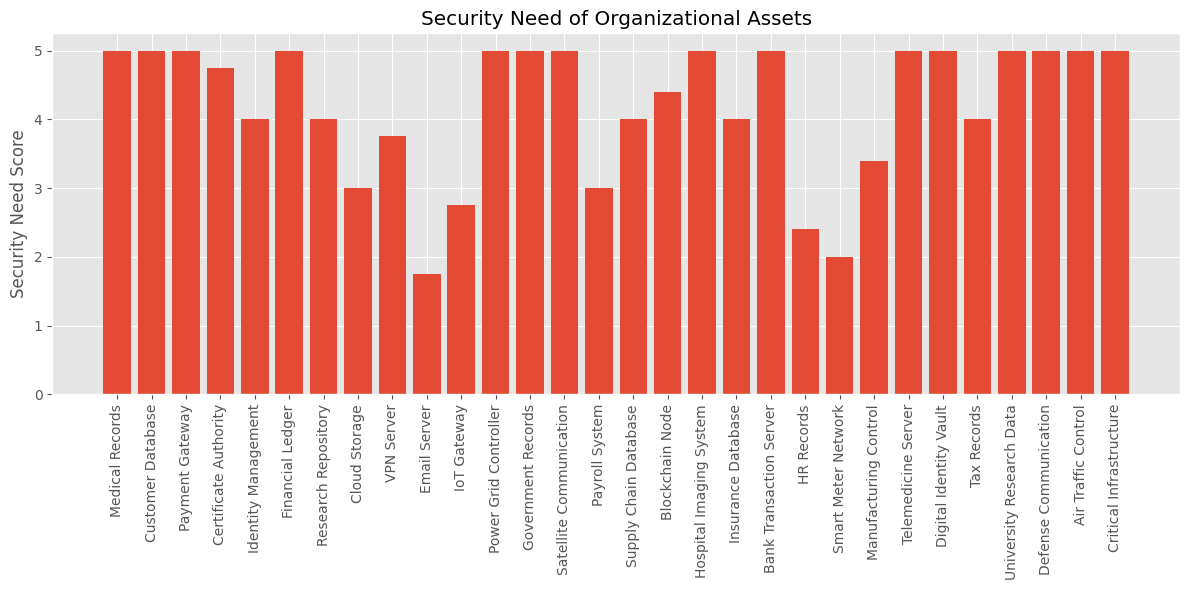

In [16]:
plt.figure(figsize=(12,6))
plt.bar(df["Asset"],df["Security_Need_Score"])
plt.xticks(rotation=90)
plt.ylabel("Security Need Score")
plt.title("Security Need of Organizational Assets")
plt.tight_layout()
plt.show()

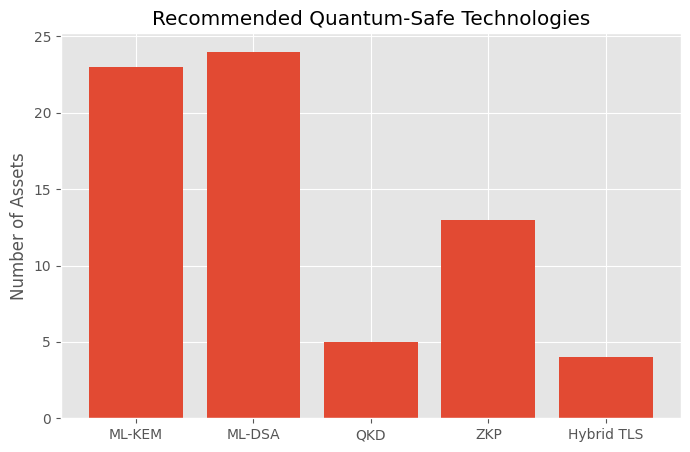

In [17]:
tech_counts = {
    "ML-KEM":0,
    "ML-DSA":0,
    "QKD":0,
    "ZKP":0,
    "Hybrid TLS":0
}

for rec in df["Recommendation"]:
    for tech in tech_counts:
        if tech in rec:
            tech_counts[tech]+=1
plt.figure(figsize=(8,5))
plt.bar(tech_counts.keys(),tech_counts.values())
plt.ylabel("Number of Assets")
plt.title("Recommended Quantum-Safe Technologies")
plt.show()

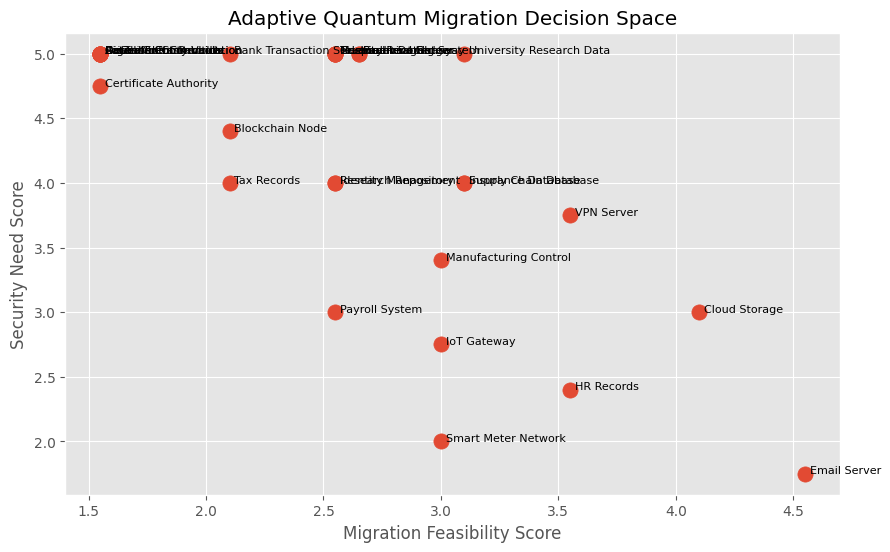

In [18]:
plt.figure(figsize=(10,6))
plt.scatter(
    df["Migration_Feasibility_Score"],
    df["Security_Need_Score"],
    s=120)
for i,row in df.iterrows():
    plt.text(
        row["Migration_Feasibility_Score"]+0.02,
        row["Security_Need_Score"],
        row["Asset"],
        fontsize=8)
plt.xlabel("Migration Feasibility Score")
plt.ylabel("Security Need Score")
plt.title("Adaptive Quantum Migration Decision Space")
plt.grid(True)
plt.show()

In [19]:
   !pip install -q scikit-fuzzy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 8.3 MB/s eta 0:00:00


In [20]:
!pip install scikit-fuzzy
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [21]:
import numpy as np
security = ctrl.Antecedent(np.arange(0,5.1,0.1),'security')
feasibility = ctrl.Antecedent(np.arange(0,5.1,0.1),'feasibility')
recommendation = ctrl.Consequent(np.arange(0,101,1),'recommendation')

In [22]:
security['low'] = fuzz.trimf(security.universe,[0,0,2.5])

security['medium'] = fuzz.trimf(security.universe,[2,3,4])

security['high'] = fuzz.trimf(security.universe,[3.5,5,5])

feasibility['low'] = fuzz.trimf(feasibility.universe,[0,0,2])

feasibility['medium'] = fuzz.trimf(feasibility.universe,[1.5,3,4])

feasibility['high'] = fuzz.trimf(feasibility.universe,[3.5,5,5])

recommendation['TLS'] = fuzz.trimf(recommendation.universe,[0,15,30])

recommendation['PQC'] = fuzz.trimf(recommendation.universe,[25,45,65])

recommendation['Hybrid'] = fuzz.trimf(recommendation.universe,[60,75,90])

recommendation['Advanced'] = fuzz.trimf(recommendation.universe,[85,100,100])

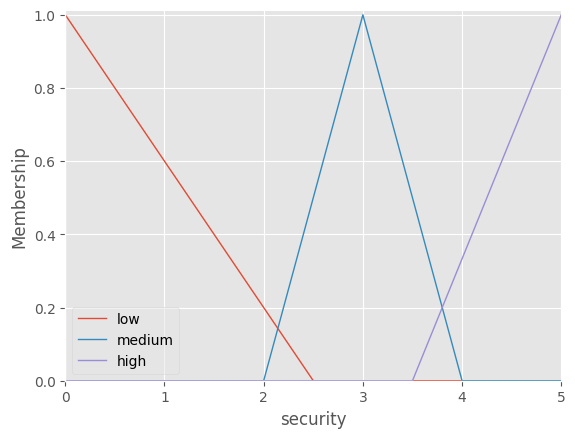

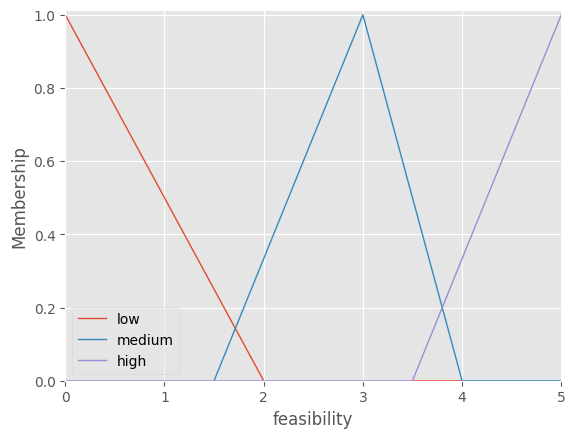

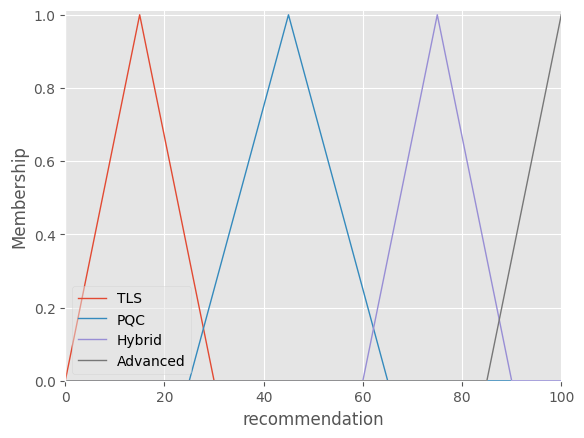

In [23]:
security.view()
feasibility.view()
recommendation.view()

In [24]:
rule1 = ctrl.Rule(
security['high'] &
feasibility['high'],
recommendation['Advanced']
)

rule2 = ctrl.Rule(
security['high'] &
feasibility['medium'],
recommendation['Hybrid']
)

rule3 = ctrl.Rule(
security['medium'] &
feasibility['high'],
recommendation['Hybrid']
)

rule4 = ctrl.Rule(
security['medium'] &
feasibility['medium'],
recommendation['PQC']
)

rule5 = ctrl.Rule(
security['low'],
recommendation['TLS']
)

In [25]:
system = ctrl.ControlSystem([
rule1,
rule2,
rule3,
rule4,
rule5
])

sim = ctrl.ControlSystemSimulation(system)

80.74025974025969


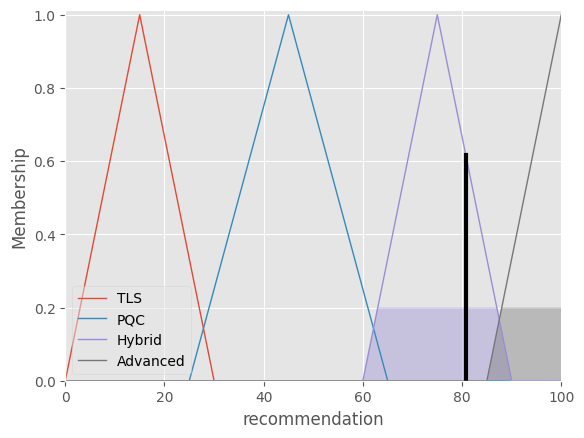

In [26]:
sim.input['security'] = 4.6
sim.input['feasibility'] = 3.8
sim.compute()
print(sim.output['recommendation'])
recommendation.view(sim=sim)

In [27]:
fuzzy_output=[]
for _,row in df.iterrows():
    sim.input['security']=row["Security_Need_Score"]
    sim.input['feasibility']=row["Migration_Feasibility_Score"]
    sim.compute()
    fuzzy_output.append(sim.output['recommendation'])
df["FuzzyScore"]=fuzzy_output

In [28]:
def fuzzy_architecture(x):
    if x<30:
        return "Hybrid TLS"
    elif x<60:
        return "ML-KEM + ML-DSA"
    elif x<85:
        return "ML-KEM + ML-DSA + ZKP"
    else:
        return "ML-KEM + ML-DSA + QKD + ZKP"
df["Fuzzy_Recommendation"]=df["FuzzyScore"].apply(
fuzzy_architecture
)

In [29]:
df[[
"Asset",
"Recommendation",
"Fuzzy_Recommendation"
]]

,Asset,Recommendation,Fuzzy_Recommendation
0,Medical Records,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP
1,Customer Database,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP
2,Payment Gateway,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
3,Certificate Authority,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
4,Identity Management,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
5,Financial Ledger,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP
6,Research Repository,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP
7,Cloud Storage,,ML-KEM + ML-DSA + ZKP
8,VPN Server,ML-DSA + ML-KEM,ML-KEM + ML-DSA
9,Email Server,Hybrid TLS,Hybrid TLS


In [30]:
comparison = df[[
    "Asset",
    "Recommendation",
    "Fuzzy_Recommendation"
]]
comparison

,Asset,Recommendation,Fuzzy_Recommendation
0,Medical Records,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP
1,Customer Database,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP
2,Payment Gateway,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
3,Certificate Authority,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
4,Identity Management,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP
5,Financial Ledger,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP
6,Research Repository,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP
7,Cloud Storage,,ML-KEM + ML-DSA + ZKP
8,VPN Server,ML-DSA + ML-KEM,ML-KEM + ML-DSA
9,Email Server,Hybrid TLS,Hybrid TLS


In [31]:
print("Rule-based Recommendations")
print(df["Recommendation"].value_counts())

print("\nFuzzy Recommendations")
print(df["Fuzzy_Recommendation"].value_counts())

Rule-based Recommendations
Recommendation
ML-DSA + ML-KEM                10
ML-DSA + ML-KEM + ZKP           8
ML-DSA + ML-KEM + QKD + ZKP     5
Hybrid TLS                      4
                                2
ML-DSA                          1
Name: count, dtype: int64

Fuzzy Recommendations
Fuzzy_Recommendation
ML-KEM + ML-DSA + ZKP    23
ML-KEM + ML-DSA           5
Hybrid TLS                2
Name: count, dtype: int64


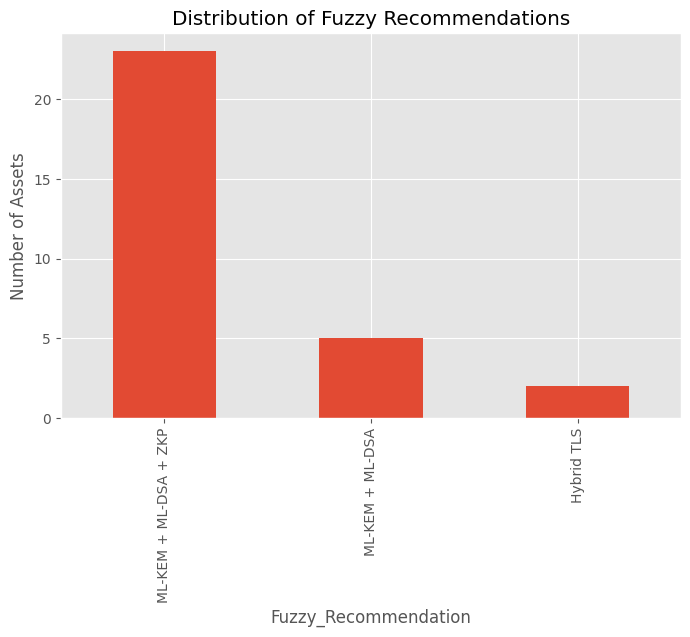

In [32]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
df["Fuzzy_Recommendation"].value_counts().plot(kind="bar")
plt.title("Distribution of Fuzzy Recommendations")
plt.ylabel("Number of Assets")
plt.show()

In [33]:
comparison = df[[
    "Asset",
    "Recommendation",
    "Fuzzy_Recommendation"
]]
comparison["Changed"] = (
    comparison["Recommendation"] != comparison["Fuzzy_Recommendation"])
comparison

/tmp/ipykernel_644/778750866.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison["Changed"] = (


,Asset,Recommendation,Fuzzy_Recommendation,Changed
0,Medical Records,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP,True
1,Customer Database,ML-DSA + ML-KEM + QKD + ZKP,ML-KEM + ML-DSA + ZKP,True
2,Payment Gateway,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP,True
3,Certificate Authority,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP,True
4,Identity Management,ML-DSA + ML-KEM,ML-KEM + ML-DSA + ZKP,True
5,Financial Ledger,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP,True
6,Research Repository,ML-DSA + ML-KEM + ZKP,ML-KEM + ML-DSA + ZKP,True
7,Cloud Storage,,ML-KEM + ML-DSA + ZKP,True
8,VPN Server,ML-DSA + ML-KEM,ML-KEM + ML-DSA,True
9,Email Server,Hybrid TLS,Hybrid TLS,False


In [34]:
test = df.copy()
test["Future_Quantum_Risk"] = 5
test["Security_Need_Score"] = (
    0.40 * test["Sensitivity"] +
    0.30 * test["Confidentiality_Lifetime"] +
    0.30 * test["Future_Quantum_Risk"])
test[["Recommendation", "Reason"]] = test.apply(
    recommend_architecture,
    axis=1)
test[[
    "Asset",
    "Future_Quantum_Risk",
    "Security_Need_Score",
    "Recommendation"
]]

,Asset,Future_Quantum_Risk,Security_Need_Score,Recommendation
0,Medical Records,5,5.0,ML-DSA + ML-KEM + QKD + ZKP
1,Customer Database,5,5.0,ML-DSA + ML-KEM + QKD + ZKP
2,Payment Gateway,5,5.0,ML-DSA + ML-KEM
3,Certificate Authority,5,5.0,ML-DSA + ML-KEM
4,Identity Management,5,4.3,ML-DSA + ML-KEM
5,Financial Ledger,5,5.0,ML-DSA + ML-KEM + ZKP
6,Research Repository,5,4.3,ML-DSA + ML-KEM + ZKP
7,Cloud Storage,5,3.6,ML-KEM
8,VPN Server,5,4.3,ML-DSA + ML-KEM
9,Email Server,5,2.9,Hybrid TLS


In [35]:
bank = df.copy()

bank["Sensitivity"] = 5
bank["Confidentiality_Lifetime"] = 5
bank["Future_Quantum_Risk"] = 5
bank["Infrastructure_Readiness"] = 4
bank["Migration_Cost"] = 3
bank["Security_Need_Score"] = (
    0.4*bank["Sensitivity"] +
    0.3*bank["Confidentiality_Lifetime"] +
    0.3*bank["Future_Quantum_Risk"])

bank["Migration_Feasibility_Score"] = (
    0.6*bank["Infrastructure_Readiness"] +
    0.4*(6-bank["Migration_Cost"]))
bank[["Recommendation","Reason"]] = bank.apply(
    recommend_architecture,
    axis=1)

bank[[
    "Asset",
    "Recommendation",
    "Reason"
]]

,Asset,Recommendation,Reason
0,Medical Records,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...
1,Customer Database,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...
2,Payment Gateway,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...
3,Certificate Authority,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...
4,Identity Management,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...
5,Financial Ledger,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...
6,Research Repository,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...
7,Cloud Storage,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...
8,VPN Server,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...
9,Email Server,ML-DSA + ML-KEM + QKD,High assurance authentication; Quantum-safe ke...


In [36]:
import numpy as np
np.random.seed(42)
# New parameters
df["Authentication_Requirement"] = np.random.randint(2,6,len(df))
df["Privacy_Requirement"] = np.random.randint(2,6,len(df))
df["Integrity_Requirement"] = np.random.randint(2,6,len(df))
df["Regulatory_Compliance"] = np.random.randint(2,6,len(df))
df["Scalability_Requirement"] = np.random.randint(2,6,len(df))
df.head()

,Asset,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Authentication,Privacy,Integrity,Infrastructure_Readiness,Migration_Cost,Security_Need_Score,...,Recommendation,Reason,Confidence,FuzzyScore,Fuzzy_Recommendation,Authentication_Requirement,Privacy_Requirement,Integrity_Requirement,Regulatory_Compliance,Scalability_Requirement
0,Medical Records,5,5,5,1,1,1,3,4,5.00,...,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...,85,75.0,ML-KEM + ML-DSA + ZKP,4,2,4,5,5
1,Customer Database,5,5,5,1,1,1,3,4,5.00,...,ML-DSA + ML-KEM + QKD + ZKP,High assurance authentication; Quantum-safe ke...,85,75.0,ML-KEM + ML-DSA + ZKP,5,2,4,5,2
2,Payment Gateway,5,5,5,1,0,1,4,5,5.00,...,ML-DSA + ML-KEM,High assurance authentication; Quantum-safe ke...,70,75.0,ML-KEM + ML-DSA + ZKP,2,5,2,3,3
3,Certificate Authority,5,5,4,1,0,1,2,5,4.75,...,ML-DSA + ML-KEM,High assurance authentication; Quantum-safe ke...,70,75.0,ML-KEM + ML-DSA + ZKP,4,3,2,3,4
4,Identity Management,4,4,4,1,0,1,3,4,4.00,...,ML-DSA + ML-KEM,High assurance authentication; Quantum-safe ke...,70,75.0,ML-KEM + ML-DSA + ZKP,4,3,4,3,2


In [37]:
architecture_map = {
"Hybrid TLS":0,
"ML-KEM":1,
"ML-KEM + ML-DSA":2,
"ML-KEM + ML-DSA + ZKP":3,
"ML-DSA + ML-KEM + QKD":4,
"ML-DSA + ML-KEM + QKD + ZKP":5
}
df["Architecture_Label"] = df["Recommendation"].map(architecture_map)
df[[
"Recommendation",
"Architecture_Label"
]].head()

,Recommendation,Architecture_Label
0,ML-DSA + ML-KEM + QKD + ZKP,5.0
1,ML-DSA + ML-KEM + QKD + ZKP,5.0
2,ML-DSA + ML-KEM,NaN
3,ML-DSA + ML-KEM,NaN
4,ML-DSA + ML-KEM,NaN


In [38]:
architecture_map = {
    "Hybrid TLS": 0,
    "ML-KEM": 1,
    "ML-KEM + ML-DSA": 2,
    "ML-DSA + ML-KEM": 2,
    "ML-KEM + ML-DSA + ZKP": 3,
    "ML-DSA + ML-KEM + ZKP": 3,
    "ML-KEM + ML-DSA + QKD": 4,
    "ML-DSA + ML-KEM + QKD": 4,
    "ML-KEM + ML-DSA + QKD + ZKP": 5,
    "ML-DSA + ML-KEM + QKD + ZKP": 5
}
df["Architecture_Label"] = df["Recommendation"].map(architecture_map)

In [39]:
print(df["Architecture_Label"].isna().sum())

3


In [40]:
print(df[df["Architecture_Label"].isna()]["Recommendation"].unique())

['' 'ML-DSA']


In [41]:
df[df["Recommendation"].isin(["", "ML-DSA"])][[
    "Asset",
    "Security_Need_Score",
    "Migration_Feasibility_Score",
    "Recommendation"
]]

,Asset,Security_Need_Score,Migration_Feasibility_Score,Recommendation
7,Cloud Storage,3.0,4.10,
14,Payroll System,3.0,2.55,
22,Manufacturing Control,3.4,3.00,ML-DSA


In [42]:
def recommend_architecture(row):

    security = row["Security_Need_Score"]
    feasibility = row["Migration_Feasibility_Score"]

    recommendation = []
    reason = []
    if security >= 3.0:
        recommendation.append("ML-KEM")
        reason.append("Quantum-safe key establishment")

    if security >= 3.5:
        recommendation.insert(0, "ML-DSA")
        reason.append("High assurance authentication")

    if security >= 4.3 and feasibility >= 3.0:
        recommendation.append("QKD")
        reason.append("Long-term confidentiality")
    if security >= 4.6:
        recommendation.append("ZKP")
        reason.append("Privacy-preserving verification")
    if len(recommendation) == 0:
        recommendation.append("Hybrid TLS")
        reason.append("Adequate for low-security assets")

    recommendation = " + ".join(recommendation)
    reason = "; ".join(reason)

    return pd.Series([recommendation, reason])

In [43]:
df[["Recommendation", "Reason"]] = df.apply(
    recommend_architecture,
    axis=1)

In [44]:
print(df["Recommendation"].unique())

['ML-DSA + ML-KEM + ZKP' 'ML-DSA + ML-KEM' 'ML-KEM' 'Hybrid TLS'
 'ML-DSA + ML-KEM + QKD + ZKP']


In [45]:
architecture_map = {
    "Hybrid TLS": 0,
    "ML-KEM": 1,
    "ML-DSA + ML-KEM": 2,
    "ML-DSA + ML-KEM + ZKP": 3,
    "ML-DSA + ML-KEM + QKD": 4,
    "ML-DSA + ML-KEM + QKD + ZKP": 5
}
df["Architecture_Label"] = df["Recommendation"].map(architecture_map)
print(df["Architecture_Label"].isna().sum())

0


In [46]:
import numpy as np
import pandas as pd
np.random.seed(42)
N = 500
synthetic = pd.DataFrame({
    "Sensitivity":np.random.randint(1,6,N),
    "Confidentiality_Lifetime":np.random.randint(1,6,N),
    "Future_Quantum_Risk":np.random.randint(1,6,N),
    "Infrastructure_Readiness":np.random.randint(1,6,N),
    "Migration_Cost":np.random.randint(1,6,N),
    "Authentication_Requirement":np.random.randint(1,6,N),
    "Privacy_Requirement":np.random.randint(1,6,N),
    "Integrity_Requirement":np.random.randint(1,6,N),
    "Regulatory_Compliance":np.random.randint(1,6,N),
    "Scalability_Requirement":np.random.randint(1,6,N)})

In [47]:
synthetic["Security_Need_Score"] = (
0.20*synthetic["Sensitivity"]
+0.15*synthetic["Confidentiality_Lifetime"]
+0.15*synthetic["Future_Quantum_Risk"]
+0.15*synthetic["Authentication_Requirement"]
+0.10*synthetic["Privacy_Requirement"]
+0.10*synthetic["Integrity_Requirement"]
+0.10*synthetic["Regulatory_Compliance"]
+0.05*synthetic["Scalability_Requirement"])

In [48]:
synthetic["Migration_Feasibility_Score"]=(
0.60*synthetic["Infrastructure_Readiness"]+0.40*(6-synthetic["Migration_Cost"]))

In [49]:
synthetic[["Recommendation","Reason"]] = synthetic.apply(recommend_architecture,axis=1)

In [50]:
synthetic["Architecture_Label"]=synthetic["Recommendation"].map(architecture_map)

In [51]:
synthetic.head()

,Sensitivity,Confidentiality_Lifetime,Future_Quantum_Risk,Infrastructure_Readiness,Migration_Cost,Authentication_Requirement,Privacy_Requirement,Integrity_Requirement,Regulatory_Compliance,Scalability_Requirement,Security_Need_Score,Migration_Feasibility_Score,Recommendation,Reason,Architecture_Label
0,4,4,4,4,4,5,3,1,3,2,3.55,3.2,ML-DSA + ML-KEM,Quantum-safe key establishment; High assurance...,2
1,5,1,4,2,3,5,5,3,5,5,4.05,2.4,ML-DSA + ML-KEM,Quantum-safe key establishment; High assurance...,2
2,3,5,4,4,2,4,1,1,2,1,3.00,4.0,ML-KEM,Quantum-safe key establishment,1
3,5,3,4,3,1,1,5,2,5,1,3.45,3.8,ML-KEM,Quantum-safe key establishment,1
4,5,3,5,1,5,5,2,3,2,4,3.85,1.0,ML-DSA + ML-KEM,Quantum-safe key establishment; High assurance...,2


In [52]:
synthetic["Architecture_Label"].value_counts()

,count
Architecture_Label,
0,248
1,164
2,86
4,2


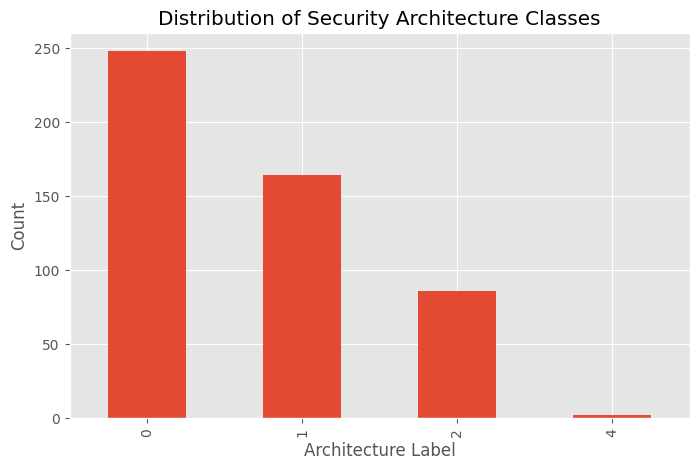

In [53]:
import matplotlib.pyplot as plt
synthetic["Architecture_Label"].value_counts().sort_index().plot(kind="bar",figsize=(8,5))
plt.xlabel("Architecture Label")
plt.ylabel("Count")
plt.title("Distribution of Security Architecture Classes")
plt.show()

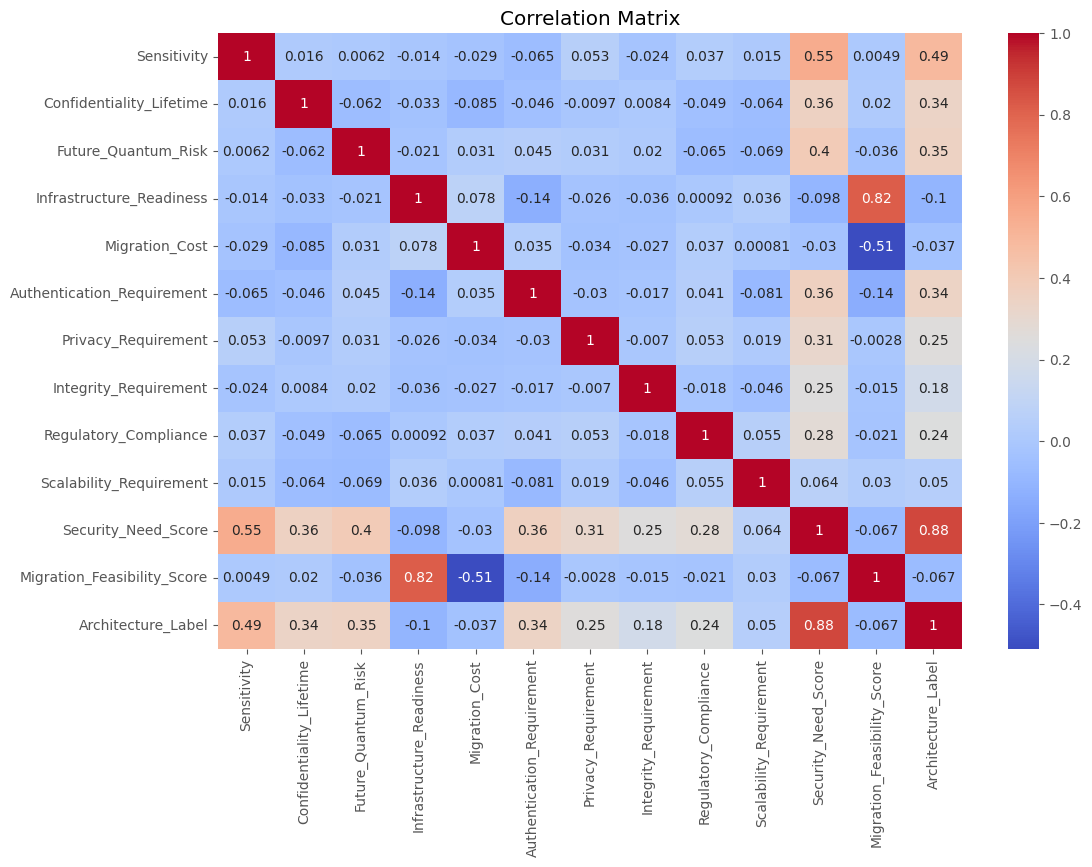

In [54]:
import seaborn as sns
plt.figure(figsize=(12,8))
sns.heatmap(
    synthetic.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

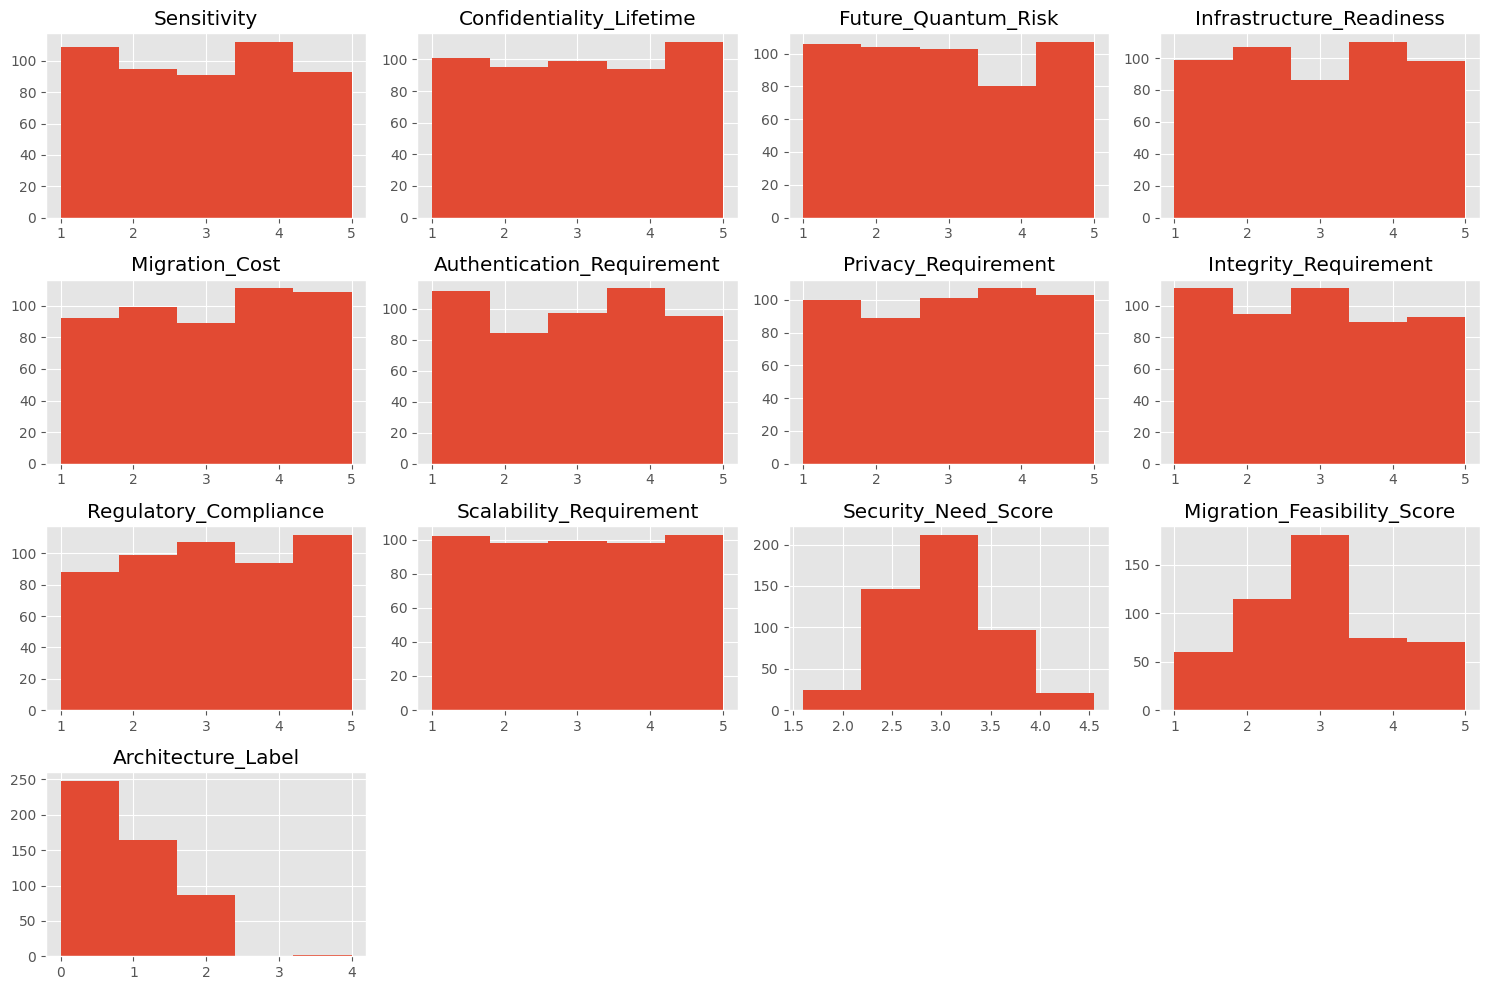

In [55]:
synthetic.hist(figsize=(15,10),bins=5)
plt.tight_layout()
plt.show()

In [56]:
def recommend_architecture_v2(row):
    security = row["Security_Need_Score"]
    feasibility = row["Migration_Feasibility_Score"]
    if security < 2.5 and feasibility < 3:
        recommendation = "Hybrid TLS"
        reason = "Low security requirement and limited migration readiness."
    elif security < 2.5 and feasibility >= 3:
        recommendation = "ML-KEM"
        reason = "Migration is feasible but security requirement is relatively low."
    elif security < 3.7 and feasibility < 3:
        recommendation = "ML-DSA + ML-KEM"
        reason = "Moderate security requirement with constrained deployment."
    elif security < 3.7 and feasibility >= 3:
        recommendation = "ML-DSA + ML-KEM + ZKP"
        reason = "Moderate security with sufficient deployment capability."
    elif security >= 3.7 and feasibility < 3:
        recommendation = "ML-DSA + ML-KEM + QKD"
        reason = "High security requirement but deployment constraints exist."
    else:
        recommendation = "ML-DSA + ML-KEM + QKD + ZKP"
        reason = "High security requirement with strong migration readiness."
    return pd.Series([recommendation, reason])

In [57]:
synthetic[["Recommendation_V2", "Reason_V2"]] = synthetic.apply(recommend_architecture_v2, axis=1)

In [58]:
synthetic["Architecture_Label_V2"] = synthetic["Recommendation_V2"].map(architecture_map)

In [59]:
synthetic["Architecture_Label_V2"].value_counts().sort_index()

,count
Architecture_Label_V2,
0,29
1,42
2,189
3,195
4,26
5,19


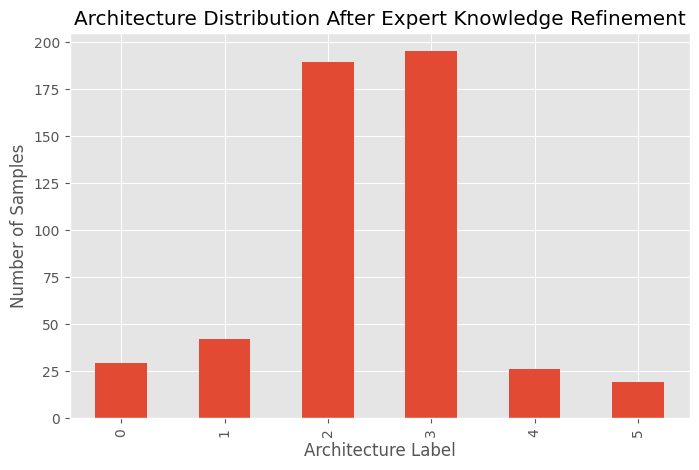

In [60]:
import matplotlib.pyplot as plt
synthetic["Architecture_Label_V2"].value_counts().sort_index().plot(kind="bar",figsize=(8,5))
plt.title("Architecture Distribution After Expert Knowledge Refinement")
plt.xlabel("Architecture Label")
plt.ylabel("Number of Samples")
plt.show()

In [61]:
synthetic["Architecture_Label_V2"].value_counts(
    normalize=True
).sort_index()

,proportion
Architecture_Label_V2,
0,0.058
1,0.084
2,0.378
3,0.390
4,0.052
5,0.038


In [62]:
import numpy as np
import pandas as pd
features = [
    "Sensitivity",
    "Confidentiality_Lifetime",
    "Future_Quantum_Risk",
    "Infrastructure_Readiness",
    "Migration_Cost",
    "Authentication_Requirement",
    "Privacy_Requirement",
    "Integrity_Requirement",
    "Regulatory_Compliance",
    "Scalability_Requirement",
    "Security_Need_Score",
    "Migration_Feasibility_Score"]

X = synthetic[features].copy()
y = synthetic["Architecture_Label_V2"].astype(int).copy()
print("Number of features:", len(features))
print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts().sort_index())

Number of features: 12
Dataset shape: (500, 12)

Class distribution:
Architecture_Label_V2
0     29
1     42
2    189
3    195
4     26
5     19
Name: count, dtype: int64


In [63]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 400
Testing samples : 100

Training class distribution:
Architecture_Label_V2
0     23
1     34
2    151
3    156
4     21
5     15
Name: count, dtype: int64

Testing class distribution:
Architecture_Label_V2
0     6
1     8
2    38
3    39
4     5
5     4
Name: count, dtype: int64


In [64]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Minimum training value:", X_train_scaled.min())
print("Maximum training value:", X_train_scaled.max())

Minimum training value: 0.0
Maximum training value: 1.0


In [65]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [66]:
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
).to(device)
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
).to(device)
y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.long
).to(device)
y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.long
).to(device)
print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train: torch.Size([400, 12])
y_train: torch.Size([400])
X_test : torch.Size([100, 12])
y_test : torch.Size([100])


In [67]:
num_classes = 6
class_counts = np.bincount(
    y_train.values,
    minlength=num_classes)
class_weights = (
    len(y_train)
    /
    (num_classes * np.maximum(class_counts, 1)))
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)
print("Class counts:")
print(class_counts)
print("\nClass weights:")
print(class_weights)

Class counts:
[ 23  34 151 156  21  15]

Class weights:
tensor([2.8986, 1.9608, 0.4415, 0.4274, 3.1746, 4.4444])


In [68]:
class ANFISClassifier(nn.Module):
    def __init__(self,n_inputs,n_rules=12,n_classes=6):
        super().__init__()
        self.n_inputs = n_inputs
        self.n_rules = n_rules
        self.n_classes = n_classes
        self.centers = nn.Parameter(
            torch.rand(n_rules, n_inputs))
        self.log_sigmas = nn.Parameter(
            torch.zeros(n_rules, n_inputs))
        self.consequents = nn.Parameter(
            torch.randn(n_rules,n_classes) * 0.05)
        self.bias = nn.Parameter(
            torch.zeros(n_classes))
    def forward(self, x):
        sigma = (F.softplus(self.log_sigmas)+ 1e-4)
        x_expanded = x.unsqueeze(1)
        membership = torch.exp(-0.5 *( (x_expanded - self.centers)/ sigma) ** 2)
        firing_strength = torch.prod(
            membership,
            dim=2)
        normalized_strength = (firing_strength/(firing_strength.sum(dim=1,keepdim=True)+ 1e-8))
        rule_outputs = (normalized_strength.unsqueeze(2)* self.consequents.unsqueeze(0))
        output = rule_outputs.sum(dim=1)
        output = output + self.bias
        return output

In [69]:
model = ANFISClassifier(
    n_inputs=len(features),
    n_rules=12,
    n_classes=num_classes
).to(device)
print(model)

ANFISClassifier()


In [70]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-4)
epochs = 500
loss_history = []
accuracy_history = []
print("Epochs:", epochs)
print("Learning rate:", 0.01)
print("Number of fuzzy rules:", 12)

Epochs: 500
Learning rate: 0.01
Number of fuzzy rules: 12


In [71]:
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(
        X_train_tensor)
    loss = criterion(
        outputs,
        y_train_tensor)
    loss.backward()
    optimizer.step()
    predictions = torch.argmax(outputs,dim=1)
    accuracy = (predictions == y_train_tensor).float().mean().item()
    loss_history.append(loss.item())
    accuracy_history.append(accuracy)
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1:03d}/{epochs}] | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.4f}")

Epoch [050/500] | Loss: 1.2571 | Accuracy: 0.6300
Epoch [100/500] | Loss: 0.7553 | Accuracy: 0.6000
Epoch [150/500] | Loss: 0.4432 | Accuracy: 0.7875
Epoch [200/500] | Loss: 0.3372 | Accuracy: 0.8125
Epoch [250/500] | Loss: 0.2898 | Accuracy: 0.8350
Epoch [300/500] | Loss: 0.2591 | Accuracy: 0.8625
Epoch [350/500] | Loss: 0.2362 | Accuracy: 0.8775
Epoch [400/500] | Loss: 0.2185 | Accuracy: 0.8925
Epoch [450/500] | Loss: 0.2040 | Accuracy: 0.8925
Epoch [500/500] | Loss: 0.1921 | Accuracy: 0.9050


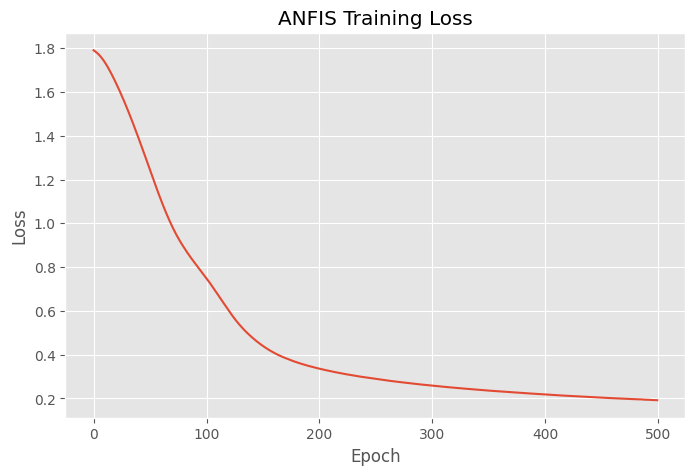

In [72]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANFIS Training Loss")
plt.grid(True)
plt.show()

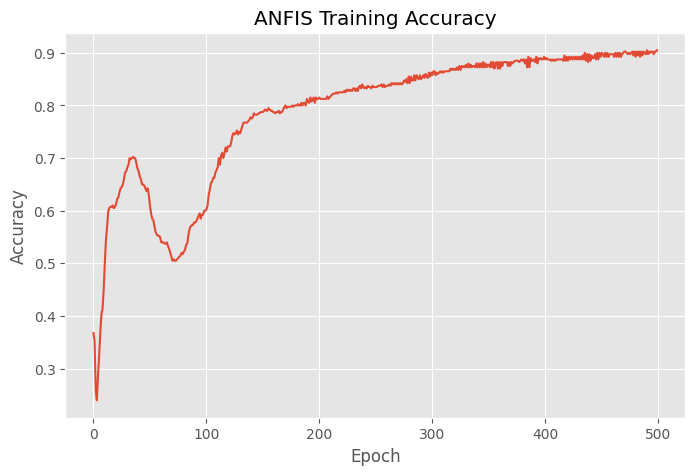

In [73]:
plt.figure(figsize=(8, 5))
plt.plot(accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANFIS Training Accuracy")
plt.grid(True)
plt.show()

In [74]:
model.eval()
with torch.no_grad():
    test_outputs = model(
        X_test_tensor)
    test_predictions = torch.argmax(
        test_outputs,
        dim=1)
test_predictions_np = (
    test_predictions
    .cpu()
    .numpy())
y_test_np = (
    y_test_tensor
    .cpu()
    .numpy())
print("Testing completed.")
print("\nFirst 20 predictions:")
print(test_predictions_np[:20])
print("\nFirst 20 actual labels:")
print(y_test_np[:20])

Testing completed.

First 20 predictions:
[5 3 2 1 2 3 2 2 3 4 4 2 2 2 4 2 3 2 1 2]

First 20 actual labels:
[3 3 2 1 2 3 2 2 3 4 4 2 2 2 4 2 3 2 3 2]


In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report)

accuracy = accuracy_score(
    y_test_np,
    test_predictions_np)
precision = precision_score(
    y_test_np,
    test_predictions_np,
    average="weighted",
    zero_division=0)
recall = recall_score(
    y_test_np,
    test_predictions_np,
    average="weighted",
    zero_division=0)
f1 = f1_score(
    y_test_np,
    test_predictions_np,
    average="weighted",
    zero_division=0)
print("=" * 45)
print("          ANFIS TEST RESULTS")
print("=" * 45)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test_np,
        test_predictions_np,
        zero_division=0))

          ANFIS TEST RESULTS
Accuracy  : 0.8400
Precision : 0.9178
Recall    : 0.8400
F1 Score  : 0.8535

Detailed Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         6
           1       0.67      1.00      0.80         8
           2       0.95      0.97      0.96        38
           3       1.00      0.67      0.80        39
           4       0.83      1.00      0.91         5
           5       0.31      1.00      0.47         4

    accuracy                           0.84       100
   macro avg       0.79      0.88      0.79       100
weighted avg       0.92      0.84      0.85       100



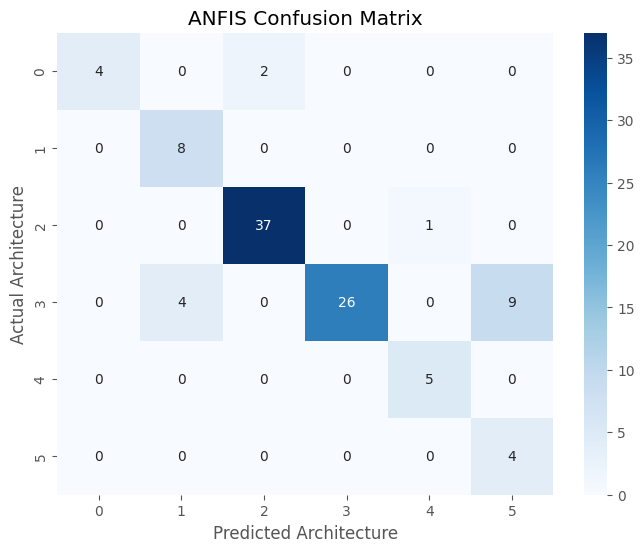

In [76]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(
    y_test_np,
    test_predictions_np,
    labels=list(range(num_classes)))
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(range(num_classes)),
    yticklabels=list(range(num_classes)))
plt.xlabel("Predicted Architecture")
plt.ylabel("Actual Architecture")
plt.title("ANFIS Confusion Matrix")
plt.show()

In [77]:
architecture_names = {
    0: "Hybrid TLS",
    1: "ML-KEM",
    2: "ML-DSA + ML-KEM",
    3: "ML-DSA + ML-KEM + ZKP",
    4: "ML-DSA + ML-KEM + QKD",
    5: "ML-DSA + ML-KEM + QKD + ZKP"
}
results = pd.DataFrame({
    "Actual_Label": y_test_np,
    "Predicted_Label": test_predictions_np
})
results["Actual_Architecture"] = (
    results["Actual_Label"]
    .map(architecture_names)
)
results["Predicted_Architecture"] = (
    results["Predicted_Label"]
    .map(architecture_names)
)
results["Correct"] = (
    results["Actual_Label"]
    ==
    results["Predicted_Label"]
)
results.head(20)

,Actual_Label,Predicted_Label,Actual_Architecture,Predicted_Architecture,Correct
0,3,5,ML-DSA + ML-KEM + ZKP,ML-DSA + ML-KEM + QKD + ZKP,False
1,3,3,ML-DSA + ML-KEM + ZKP,ML-DSA + ML-KEM + ZKP,True
2,2,2,ML-DSA + ML-KEM,ML-DSA + ML-KEM,True
3,1,1,ML-KEM,ML-KEM,True
4,2,2,ML-DSA + ML-KEM,ML-DSA + ML-KEM,True
5,3,3,ML-DSA + ML-KEM + ZKP,ML-DSA + ML-KEM + ZKP,True
6,2,2,ML-DSA + ML-KEM,ML-DSA + ML-KEM,True
7,2,2,ML-DSA + ML-KEM,ML-DSA + ML-KEM,True
8,3,3,ML-DSA + ML-KEM + ZKP,ML-DSA + ML-KEM + ZKP,True
9,4,4,ML-DSA + ML-KEM + QKD,ML-DSA + ML-KEM + QKD,True


CLASS WISE ANFIS ERROR ANALYSIS

In [78]:
analysis_results = pd.DataFrame({
    "Actual": y_test_np,
    "Predicted": test_predictions_np})
errors = analysis_results[
    analysis_results["Actual"] != analysis_results["Predicted"]].copy()
errors["Actual_Architecture"] = errors["Actual"].map(
    architecture_names)
errors["Predicted_Architecture"] = errors["Predicted"].map(
    architecture_names)
print("Total test samples:", len(analysis_results))
print("Total misclassified:", len(errors))
print(
    "Test accuracy:",
    (1 - len(errors) / len(analysis_results)))
print("\nMisclassification pairs:")
print(
    errors.groupby(
        ["Actual_Architecture", "Predicted_Architecture"]
    ).size().sort_values(ascending=False))

Total test samples: 100
Total misclassified: 16
Test accuracy: 0.84

Misclassification pairs:
Actual_Architecture    Predicted_Architecture     
ML-DSA + ML-KEM + ZKP  ML-DSA + ML-KEM + QKD + ZKP    9
                       ML-KEM                         4
Hybrid TLS             ML-DSA + ML-KEM                2
ML-DSA + ML-KEM        ML-DSA + ML-KEM + QKD          1
dtype: int64


FEATURE PROFILE

In [79]:
class3_data = synthetic[
    synthetic["Architecture_Label_V2"] == 3
][features]
class5_data = synthetic[
    synthetic["Architecture_Label_V2"] == 5
][features]
comparison = pd.DataFrame({
    "Class_3_Mean": class3_data.mean(),
    "Class_5_Mean": class5_data.mean(),
    "Difference": (
        class3_data.mean()
        -
        class5_data.mean())})
comparison.sort_values(
    "Difference",
    key=abs,
    ascending=False)

,Class_3_Mean,Class_5_Mean,Difference
Sensitivity,3.082051,4.473684,-1.391633
Confidentiality_Lifetime,3.128205,4.368421,-1.240216
Privacy_Requirement,3.112821,4.157895,-1.045074
Security_Need_Score,3.047179,3.973684,-0.926505
Authentication_Requirement,2.933333,3.789474,-0.856140
Regulatory_Compliance,3.061538,3.842105,-0.780567
Future_Quantum_Risk,2.979487,3.684211,-0.704723
Infrastructure_Readiness,4.035897,3.526316,0.509582
Scalability_Requirement,3.123077,3.526316,-0.403239
Migration_Cost,2.625641,2.315789,0.309852


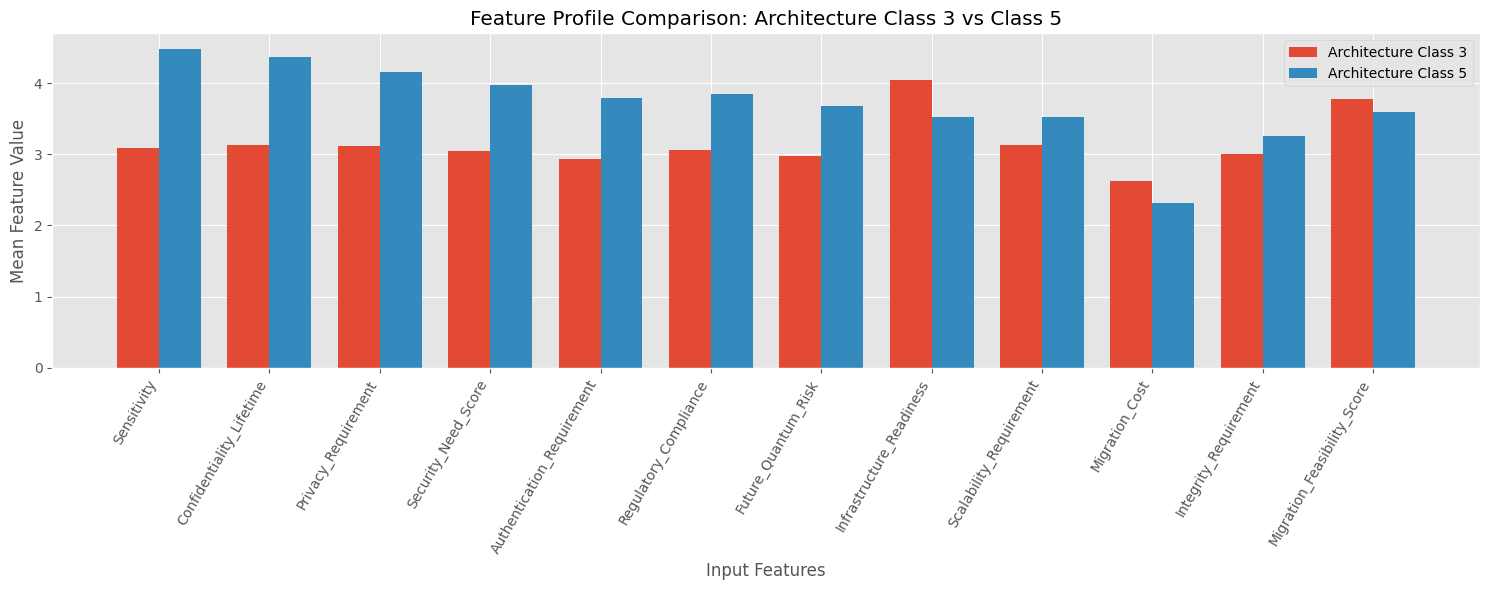

In [80]:
import numpy as np
import matplotlib.pyplot as plt
features_to_plot = ["Sensitivity","Confidentiality_Lifetime","Privacy_Requirement",
                    "Security_Need_Score","Authentication_Requirement","Regulatory_Compliance",
                    "Future_Quantum_Risk","Infrastructure_Readiness","Scalability_Requirement",
                    "Migration_Cost","Integrity_Requirement","Migration_Feasibility_Score"]
x = np.arange(len(features_to_plot))
width = 0.38
plt.figure(figsize=(15,6))
plt.bar(x - width/2, comparison.loc[features_to_plot,"Class_3_Mean"], width, label="Architecture Class 3")
plt.bar(x + width/2, comparison.loc[features_to_plot,"Class_5_Mean"], width, label="Architecture Class 5")
plt.xticks(x, features_to_plot, rotation=60, ha="right")
plt.ylabel("Mean Feature Value")
plt.xlabel("Input Features")
plt.title("Feature Profile Comparison: Architecture Class 3 vs Class 5")
plt.legend()
plt.tight_layout()
plt.show()

MODIFYING ANFIS (INCREASED FUZZY RULE CAPACITY)

In [81]:
model_v2 = ANFISClassifier(n_inputs=len(features), n_rules=24, n_classes=num_classes).to(device)
criterion_v2 = nn.CrossEntropyLoss(weight=class_weights)
optimizer_v2 = torch.optim.Adam(model_v2.parameters(), lr=0.01, weight_decay=1e-4)
epochs_v2 = 500
loss_history_v2 = []
accuracy_history_v2 = []
print("ANFIS-V2 initialized")
print("Number of fuzzy rules:", 24)
print("Number of input features:", len(features))
print("Number of output classes:", num_classes)

ANFIS-V2 initialized
Number of fuzzy rules: 24
Number of input features: 12
Number of output classes: 6


In [82]:
for epoch in range(epochs_v2):
    model_v2.train()
    optimizer_v2.zero_grad()
    outputs_v2 = model_v2(X_train_tensor)
    loss_v2 = criterion_v2(outputs_v2, y_train_tensor)
    loss_v2.backward()
    optimizer_v2.step()
    predictions_v2 = torch.argmax(outputs_v2, dim=1)
    accuracy_v2 = (predictions_v2 == y_train_tensor).float().mean().item()
    loss_history_v2.append(loss_v2.item())
    accuracy_history_v2.append(accuracy_v2)
    if (epoch + 1) % 50 == 0:
        print(f"Epoch [{epoch+1:03d}/{epochs_v2}] | Loss: {loss_v2.item():.4f} | Accuracy: {accuracy_v2:.4f}")

Epoch [050/500] | Loss: 1.2635 | Accuracy: 0.7125
Epoch [100/500] | Loss: 0.6946 | Accuracy: 0.8200
Epoch [150/500] | Loss: 0.3008 | Accuracy: 0.9650
Epoch [200/500] | Loss: 0.1355 | Accuracy: 0.9975
Epoch [250/500] | Loss: 0.0758 | Accuracy: 0.9975
Epoch [300/500] | Loss: 0.0508 | Accuracy: 1.0000
Epoch [350/500] | Loss: 0.0381 | Accuracy: 1.0000
Epoch [400/500] | Loss: 0.0307 | Accuracy: 1.0000
Epoch [450/500] | Loss: 0.0258 | Accuracy: 1.0000
Epoch [500/500] | Loss: 0.0222 | Accuracy: 1.0000


In [83]:
model_v2.eval()
with torch.no_grad():
    test_outputs_v2 = model_v2(X_test_tensor)
    test_predictions_v2 = torch.argmax(test_outputs_v2, dim=1)

test_predictions_v2_np = test_predictions_v2.cpu().numpy()
print("ANFIS-V2 testing completed.")

ANFIS-V2 testing completed.


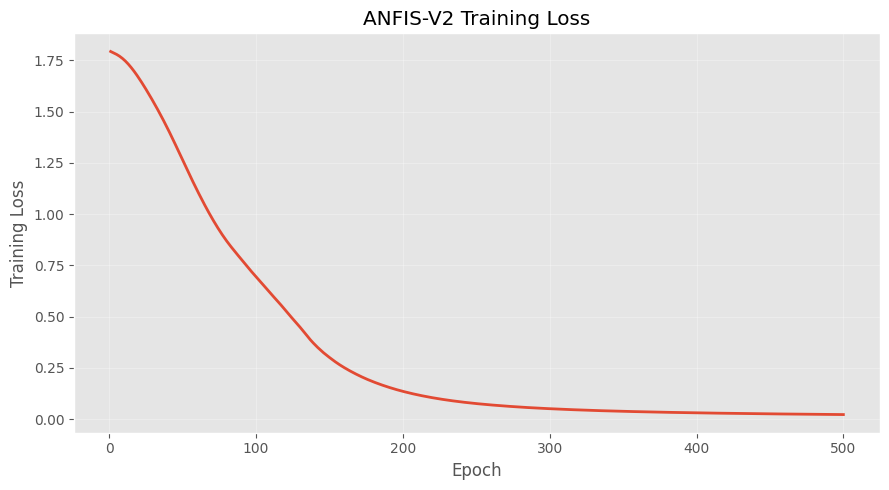

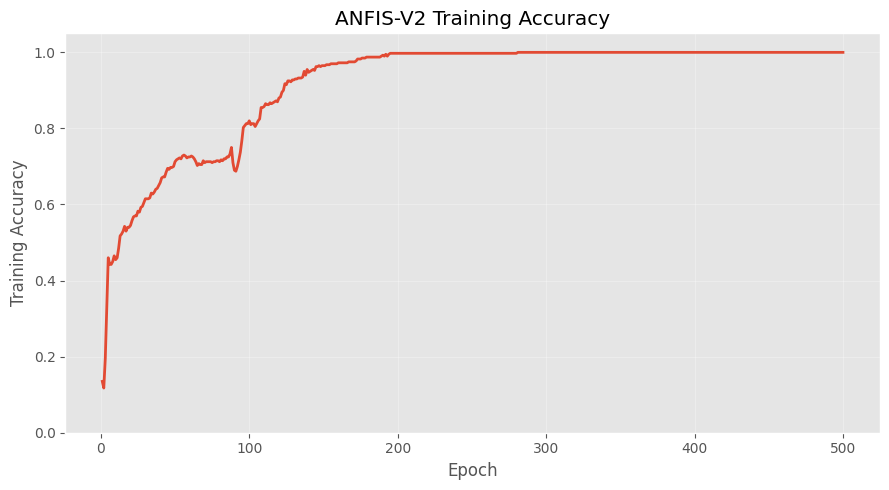

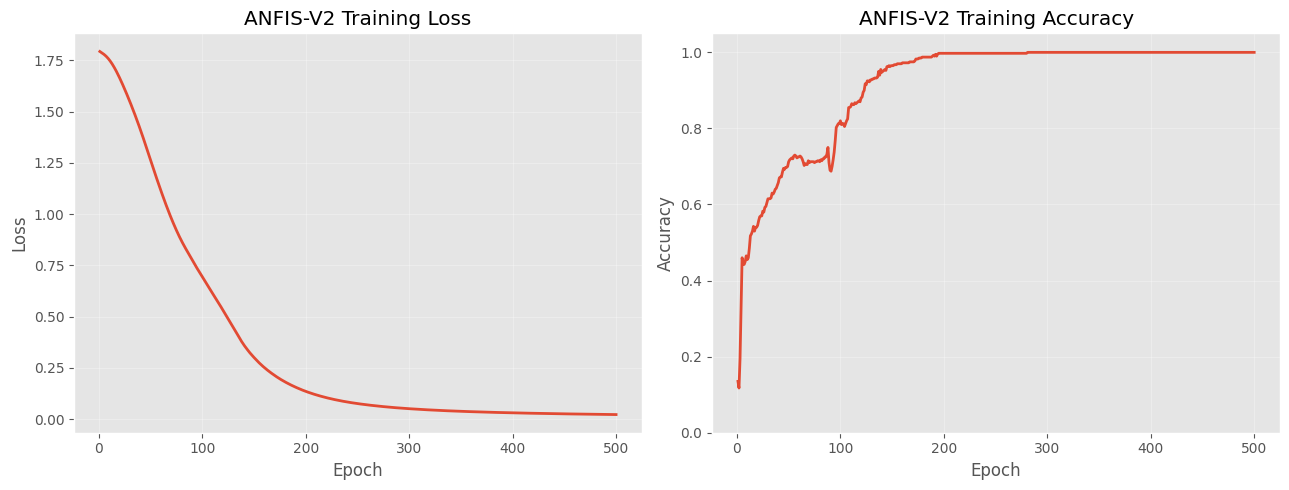

In [84]:
import matplotlib.pyplot as plt

epochs = range(1, epochs_v2 + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, loss_history_v2, linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("ANFIS-V2 Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs, accuracy_history_v2, linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("ANFIS-V2 Training Accuracy")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



import matplotlib.pyplot as plt

epochs = range(1, epochs_v2 + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))


ax[0].plot(epochs, loss_history_v2, linewidth=2)
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].set_title("ANFIS-V2 Training Loss")
ax[0].grid(True, alpha=0.3)


ax[1].plot(epochs, accuracy_history_v2, linewidth=2)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].set_title("ANFIS-V2 Training Accuracy")
ax[1].set_ylim(0, 1.05)
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [85]:
accuracy_v2 = accuracy_score(y_test_np, test_predictions_v2_np)
precision_v2 = precision_score(y_test_np, test_predictions_v2_np, average="weighted", zero_division=0)
recall_v2 = recall_score(y_test_np, test_predictions_v2_np, average="weighted", zero_division=0)
f1_v2 = f1_score(y_test_np, test_predictions_v2_np, average="weighted", zero_division=0)
macro_f1_v2 = f1_score(y_test_np, test_predictions_v2_np, average="macro", zero_division=0)
print("=" * 45)
print("          ANFIS-V2 TEST RESULTS")
print("=" * 45)
print(f"Accuracy       : {accuracy_v2:.4f}")
print(f"Precision      : {precision_v2:.4f}")
print(f"Recall         : {recall_v2:.4f}")
print(f"Weighted F1    : {f1_v2:.4f}")
print(f"Macro F1       : {macro_f1_v2:.4f}")

          ANFIS-V2 TEST RESULTS
Accuracy       : 0.9300
Precision      : 0.9330
Recall         : 0.9300
Weighted F1    : 0.9301
Macro F1       : 0.8987


In [86]:
#COMPARE
comparison_results = pd.DataFrame({
    "Model": ["ANFIS-V1", "ANFIS-V2"],
    "Fuzzy_Rules": [12, 24],
    "Accuracy": [accuracy, accuracy_v2],
    "Weighted_F1": [f1, f1_v2],
    "Macro_F1": [f1_score(y_test_np, test_predictions_np, average="macro", zero_division=0), macro_f1_v2]})
comparison_results

,Model,Fuzzy_Rules,Accuracy,Weighted_F1,Macro_F1
0,ANFIS-V1,12,0.84,0.853473,0.790120
1,ANFIS-V2,24,0.93,0.930070,0.898669


In [87]:
print(classification_report(y_test_np, test_predictions_v2_np, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     1.0000    0.8333    0.9091         6
           1     0.8889    1.0000    0.9412         8
           2     0.9722    0.9211    0.9459        38
           3     0.9250    0.9487    0.9367        39
           4     0.8333    1.0000    0.9091         5
           5     0.7500    0.7500    0.7500         4

    accuracy                         0.9300       100
   macro avg     0.8949    0.9089    0.8987       100
weighted avg     0.9330    0.9300    0.9301       100



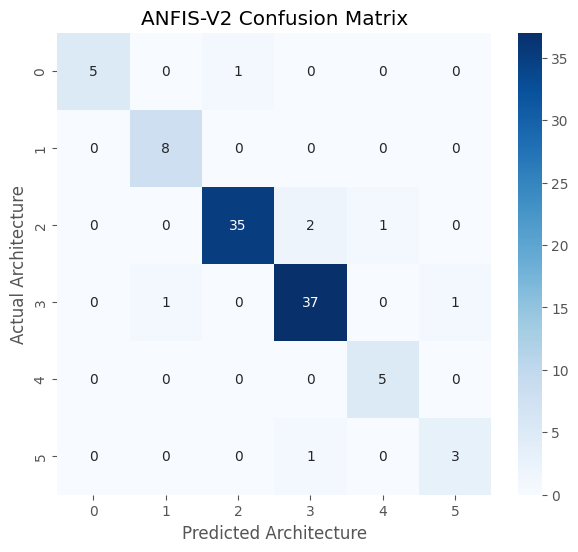

In [88]:
cm_v2 = confusion_matrix(y_test_np, test_predictions_v2_np)
plt.figure(figsize=(7,6))
sns.heatmap(cm_v2, annot=True, fmt="d", cmap="Blues", xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel("Predicted Architecture")
plt.ylabel("Actual Architecture")
plt.title("ANFIS-V2 Confusion Matrix")
plt.show()

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

seeds = [42,52,62,72,82]
robustness_results = []

for seed in seeds:
    X_tr,X_te,y_tr,y_te = train_test_split(X,y,test_size=0.20,stratify=y,random_state=seed)

    X_tr_np = X_tr.to_numpy(dtype=np.float32)
    X_te_np = X_te.to_numpy(dtype=np.float32)
    y_tr_np = np.asarray(y_tr,dtype=np.int64)
    y_te_np = np.asarray(y_te,dtype=np.int64)

    X_tr_tensor = torch.tensor(X_tr_np,dtype=torch.float32).to(device)
    X_te_tensor = torch.tensor(X_te_np,dtype=torch.float32).to(device)
    y_tr_tensor = torch.tensor(y_tr_np,dtype=torch.long).to(device)

    model_temp = ANFISClassifier(n_inputs=len(features),n_rules=24,n_classes=num_classes).to(device)

    criterion_temp = nn.CrossEntropyLoss()
    optimizer_temp = torch.optim.Adam(model_temp.parameters(),lr=0.01,weight_decay=1e-4)

    model_temp.train()

    for epoch in range(500):
        optimizer_temp.zero_grad()
        output_temp = model_temp(X_tr_tensor)
        loss_temp = criterion_temp(output_temp,y_tr_tensor)
        loss_temp.backward()
        optimizer_temp.step()

    model_temp.eval()

    with torch.no_grad():
        pred_temp = torch.argmax(model_temp(X_te_tensor),dim=1).cpu().numpy()

    acc_temp = accuracy_score(y_te_np,pred_temp)
    macro_f1_temp = f1_score(y_te_np,pred_temp,average="macro",zero_division=0)
    weighted_f1_temp = f1_score(y_te_np,pred_temp,average="weighted",zero_division=0)

    robustness_results.append([seed,acc_temp,weighted_f1_temp,macro_f1_temp])

robustness_df = pd.DataFrame(robustness_results,columns=["Seed","Accuracy","Weighted_F1","Macro_F1"])

display(robustness_df)

,Seed,Accuracy,Weighted_F1,Macro_F1
0,42,0.39,0.218849,0.093525
1,52,0.39,0.218849,0.093525
2,62,0.39,0.218849,0.093525
3,72,0.39,0.218849,0.093525
4,82,0.39,0.218849,0.093525


In [90]:
print("=============================================")
print("       ANFIS-V2 ROBUSTNESS VALIDATION")
print("=============================================")
print(f"Mean Accuracy    : {robustness_df['Accuracy'].mean():.4f}")
print(f"Std Accuracy     : {robustness_df['Accuracy'].std():.4f}")
print(f"Mean Weighted F1 : {robustness_df['Weighted_F1'].mean():.4f}")
print(f"Mean Macro F1    : {robustness_df['Macro_F1'].mean():.4f}")
print(f"Std Macro F1     : {robustness_df['Macro_F1'].std():.4f}")

       ANFIS-V2 ROBUSTNESS VALIDATION
Mean Accuracy    : 0.3900
Std Accuracy     : 0.0000
Mean Weighted F1 : 0.2188
Mean Macro F1    : 0.0935
Std Macro F1     : 0.0000


In [91]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score,f1_score
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

seeds = [42,52,62,72,82]
robustness_results = []

for seed in seeds:
    np.random.seed(seed)
    torch.manual_seed(seed)

    X_tr,X_te,y_tr,y_te = train_test_split(X,y,test_size=0.20,stratify=y,random_state=seed)

    scaler_temp = MinMaxScaler()
    X_tr_scaled = scaler_temp.fit_transform(X_tr).astype(np.float32)
    X_te_scaled = scaler_temp.transform(X_te).astype(np.float32)

    y_tr_np = np.asarray(y_tr,dtype=np.int64)
    y_te_np = np.asarray(y_te,dtype=np.int64)

    X_tr_tensor = torch.tensor(X_tr_scaled,dtype=torch.float32).to(device)
    X_te_tensor = torch.tensor(X_te_scaled,dtype=torch.float32).to(device)
    y_tr_tensor = torch.tensor(y_tr_np,dtype=torch.long).to(device)

    class_counts_temp = np.bincount(y_tr_np,minlength=num_classes)
    class_weights_temp = len(y_tr_np)/(num_classes*np.maximum(class_counts_temp,1))
    class_weights_temp = torch.tensor(class_weights_temp,dtype=torch.float32).to(device)

    model_temp = ANFISClassifier(n_inputs=len(features),n_rules=24,n_classes=num_classes).to(device)

    criterion_temp = nn.CrossEntropyLoss(weight=class_weights_temp)
    optimizer_temp = torch.optim.Adam(model_temp.parameters(),lr=0.01,weight_decay=1e-4)

    model_temp.train()

    for epoch in range(500):
        optimizer_temp.zero_grad()
        output_temp = model_temp(X_tr_tensor)
        loss_temp = criterion_temp(output_temp,y_tr_tensor)
        loss_temp.backward()
        optimizer_temp.step()

    model_temp.eval()

    with torch.no_grad():
        pred_temp = torch.argmax(model_temp(X_te_tensor),dim=1).cpu().numpy()

    acc_temp = accuracy_score(y_te_np,pred_temp)
    weighted_f1_temp = f1_score(y_te_np,pred_temp,average="weighted",zero_division=0)
    macro_f1_temp = f1_score(y_te_np,pred_temp,average="macro",zero_division=0)

    robustness_results.append([seed,acc_temp,weighted_f1_temp,macro_f1_temp])

robustness_df = pd.DataFrame(robustness_results,columns=["Seed","Accuracy","Weighted_F1","Macro_F1"])
display(robustness_df)

,Seed,Accuracy,Weighted_F1,Macro_F1
0,42,0.95,0.948356,0.904429
1,52,0.95,0.950771,0.914471
2,62,0.96,0.960527,0.921311
3,72,0.93,0.932952,0.874206
4,82,0.94,0.940909,0.882593


In [92]:
mean_accuracy = robustness_df["Accuracy"].mean()
std_accuracy = robustness_df["Accuracy"].std()
mean_weighted_f1 = robustness_df["Weighted_F1"].mean()
std_weighted_f1 = robustness_df["Weighted_F1"].std()
mean_macro_f1 = robustness_df["Macro_F1"].mean()
std_macro_f1 = robustness_df["Macro_F1"].std()

print("=============================================")
print("       ANFIS-V2 ROBUSTNESS RESULTS")
print("=============================================")
print(f"Accuracy       : {mean_accuracy:.4f} ± {std_accuracy:.4f}")
print(f"Weighted F1    : {mean_weighted_f1:.4f} ± {std_weighted_f1:.4f}")
print(f"Macro F1       : {mean_macro_f1:.4f} ± {std_macro_f1:.4f}")

       ANFIS-V2 ROBUSTNESS RESULTS
Accuracy       : 0.9460 ± 0.0114
Weighted F1    : 0.9467 ± 0.0104
Macro F1       : 0.8994 ± 0.0203


MINORITY CLASS ANALYSIS

In [93]:
minority_classes = [0,1,4,5]
minority_analysis = []
for seed in seeds:
    X_tr,X_te,y_tr,y_te = train_test_split(X,y,test_size=0.20,stratify=y,random_state=seed)
    scaler_temp = MinMaxScaler()
    X_tr_scaled = scaler_temp.fit_transform(X_tr).astype(np.float32)
    X_te_scaled = scaler_temp.transform(X_te).astype(np.float32)
    y_tr_np = np.asarray(y_tr,dtype=np.int64)
    y_te_np = np.asarray(y_te,dtype=np.int64)
    X_tr_tensor = torch.tensor(X_tr_scaled,dtype=torch.float32).to(device)
    X_te_tensor = torch.tensor(X_te_scaled,dtype=torch.float32).to(device)
    y_tr_tensor = torch.tensor(y_tr_np,dtype=torch.long).to(device)

    class_counts_temp = np.bincount(y_tr_np,minlength=num_classes)
    class_weights_temp = len(y_tr_np)/(num_classes*np.maximum(class_counts_temp,1))
    class_weights_temp = torch.tensor(class_weights_temp,dtype=torch.float32).to(device)

    torch.manual_seed(seed)
    model_temp = ANFISClassifier(n_inputs=len(features),n_rules=24,n_classes=num_classes).to(device)
    criterion_temp = nn.CrossEntropyLoss(weight=class_weights_temp)
    optimizer_temp = torch.optim.Adam(model_temp.parameters(),lr=0.01,weight_decay=1e-4)

    for epoch in range(500):
        optimizer_temp.zero_grad()
        output_temp = model_temp(X_tr_tensor)
        loss_temp = criterion_temp(output_temp,y_tr_tensor)
        loss_temp.backward()
        optimizer_temp.step()

    model_temp.eval()

    with torch.no_grad():
        pred_temp = torch.argmax(model_temp(X_te_tensor),dim=1).cpu().numpy()

    report_temp = classification_report(y_te_np,pred_temp,output_dict=True,zero_division=0)

    for cls in minority_classes:
        minority_analysis.append([seed,cls,report_temp[str(cls)]["precision"],report_temp[str(cls)]["recall"],report_temp[str(cls)]["f1-score"],report_temp[str(cls)]["support"]])

minority_df = pd.DataFrame(minority_analysis,columns=["Seed","Class","Precision","Recall","F1","Support"])
display(minority_df)

,Seed,Class,Precision,Recall,F1,Support
0,42,0,1.000000,0.666667,0.800000,6.0
1,42,1,0.888889,1.000000,0.941176,8.0
2,42,4,1.000000,1.000000,1.000000,5.0
3,42,5,0.750000,0.750000,0.750000,4.0
4,52,0,0.857143,1.000000,0.923077,6.0
5,52,1,0.888889,1.000000,0.941176,8.0
6,52,4,0.800000,0.800000,0.800000,5.0
7,52,5,0.800000,1.000000,0.888889,4.0
8,62,0,0.714286,0.833333,0.769231,6.0
9,62,1,0.888889,1.000000,0.941176,8.0


In [94]:
minority_summary = minority_df.groupby("Class")[["Precision","Recall","F1"]].agg(["mean","std"]).round(4)
display(minority_summary)

Precision         Recall              F1        
           mean     std   mean     std    mean     std
Class                                                 
0        0.8571  0.1429  0.800  0.1394  0.8123  0.0638
1        0.8564  0.1431  0.975  0.0559  0.9038  0.0794
4        0.9267  0.1011  0.960  0.0894  0.9418  0.0885
5        0.8100  0.1084  0.800  0.1118  0.7992  0.0683

FEATURE INFLUENCE ANALYSIS

In [95]:
from sklearn.metrics import accuracy_score

model_v2.eval()

X_test_np = X_test_scaled.copy()
y_test_np_local = np.asarray(y_test,dtype=np.int64)

with torch.no_grad():
    base_output = model_v2(torch.tensor(X_test_np,dtype=torch.float32).to(device))
    base_predictions = torch.argmax(base_output,dim=1).cpu().numpy()

base_accuracy = accuracy_score(y_test_np_local,base_predictions)

importance_results = []

for i,feature_name in enumerate(features):
    X_permuted = X_test_np.copy()
    np.random.seed(42+i)
    np.random.shuffle(X_permuted[:,i])

    with torch.no_grad():
        permuted_output = model_v2(torch.tensor(X_permuted,dtype=torch.float32).to(device))
        permuted_predictions = torch.argmax(permuted_output,dim=1).cpu().numpy()

    permuted_accuracy = accuracy_score(y_test_np_local,permuted_predictions)
    importance = base_accuracy - permuted_accuracy

    importance_results.append([feature_name,importance])

feature_importance_df = pd.DataFrame(importance_results,columns=["Feature","Importance"])
feature_importance_df = feature_importance_df.sort_values("Importance",ascending=False)

display(feature_importance_df)

,Feature,Importance
11,Migration_Feasibility_Score,0.41
10,Security_Need_Score,0.29
0,Sensitivity,0.08
3,Infrastructure_Readiness,0.07
4,Migration_Cost,0.07
2,Future_Quantum_Risk,0.03
9,Scalability_Requirement,0.00
6,Privacy_Requirement,0.00
8,Regulatory_Compliance,0.00
1,Confidentiality_Lifetime,-0.01


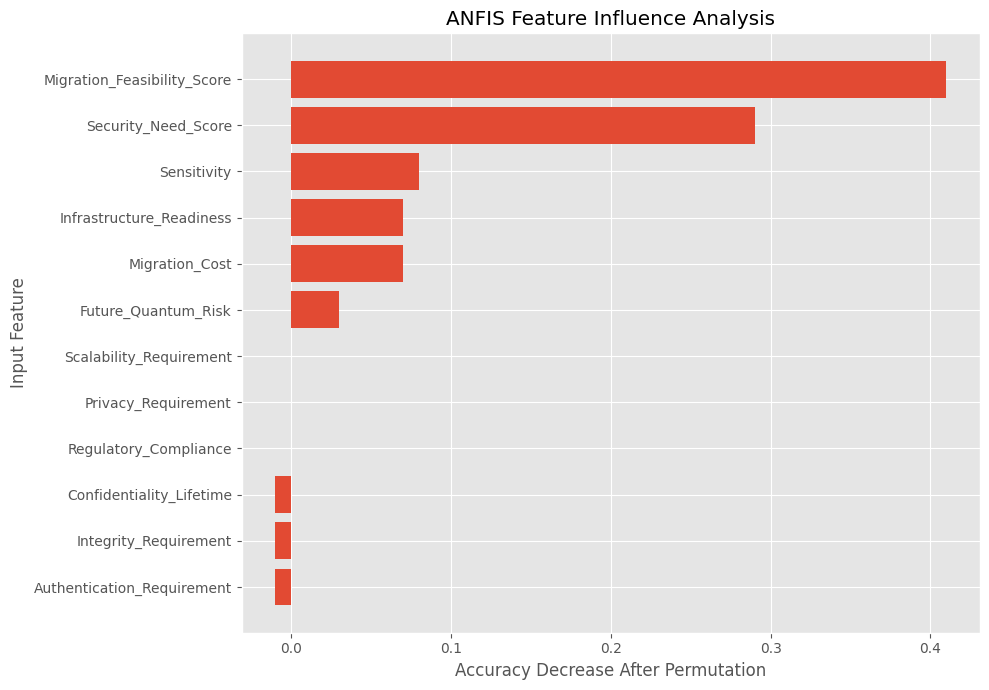

In [96]:
plt.figure(figsize=(10,7))
plt.barh(feature_importance_df["Feature"],feature_importance_df["Importance"])
plt.xlabel("Accuracy Decrease After Permutation")
plt.ylabel("Input Feature")
plt.title("ANFIS Feature Influence Analysis")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

ABLATION EXPERIMENT

In [97]:
print("Original X shape:",X.shape)
print("Original y shape:",np.asarray(y).shape)

ablation_features = [f for f in X.columns if f not in ["Security_Need_Score","Migration_Feasibility_Score"]]

X_ablation = X[ablation_features].copy()
y_ablation = np.asarray(y,dtype=np.int64)

print("Ablation X shape:",X_ablation.shape)
print("Ablation y shape:",y_ablation.shape)
print("Classes:",np.unique(y_ablation))

X_train_a,X_test_a,y_train_a,y_test_a = train_test_split(X_ablation,y_ablation,test_size=0.20,stratify=y_ablation,random_state=42)

scaler_a = MinMaxScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a).astype(np.float32)
X_test_a_scaled = scaler_a.transform(X_test_a).astype(np.float32)

X_train_a_tensor = torch.tensor(X_train_a_scaled,dtype=torch.float32).to(device)
X_test_a_tensor = torch.tensor(X_test_a_scaled,dtype=torch.float32).to(device)
y_train_a_tensor = torch.tensor(y_train_a,dtype=torch.long).to(device)

class_counts_a = np.bincount(y_train_a,minlength=num_classes)
class_weights_a = len(y_train_a)/(num_classes*np.maximum(class_counts_a,1))
class_weights_a = torch.tensor(class_weights_a,dtype=torch.float32).to(device)

torch.manual_seed(42)

ablation_model = ANFISClassifier(n_inputs=len(ablation_features),n_rules=24,n_classes=num_classes).to(device)

criterion_a = nn.CrossEntropyLoss(weight=class_weights_a)
optimizer_a = torch.optim.Adam(ablation_model.parameters(),lr=0.01,weight_decay=1e-4)

for epoch in range(500):
    optimizer_a.zero_grad()
    output_a = ablation_model(X_train_a_tensor)
    loss_a = criterion_a(output_a,y_train_a_tensor)
    loss_a.backward()
    optimizer_a.step()

ablation_model.eval()

with torch.no_grad():
    pred_a = torch.argmax(ablation_model(X_test_a_tensor),dim=1).cpu().numpy()

ablation_accuracy = accuracy_score(y_test_a,pred_a)
ablation_weighted_f1 = f1_score(y_test_a,pred_a,average="weighted",zero_division=0)
ablation_macro_f1 = f1_score(y_test_a,pred_a,average="macro",zero_division=0)

print("=============================================")
print("       ANFIS-V2 ABLATION RESULTS")
print("=============================================")
print(f"Accuracy       : {ablation_accuracy:.4f}")
print(f"Weighted F1    : {ablation_weighted_f1:.4f}")
print(f"Macro F1       : {ablation_macro_f1:.4f}")

Original X shape: (500, 12)
Original y shape: (500,)
Ablation X shape: (500, 10)
Ablation y shape: (500,)
Classes: [0 1 2 3 4 5]
       ANFIS-V2 ABLATION RESULTS
Accuracy       : 0.8200
Weighted F1    : 0.8164
Macro F1       : 0.6448


In [98]:
X_train_a,X_test_a,y_train_a,y_test_a = train_test_split(X_ablation,y_ablation,test_size=0.20,stratify=y_ablation,random_state=42)

scaler_a = MinMaxScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a).astype(np.float32)
X_test_a_scaled = scaler_a.transform(X_test_a).astype(np.float32)

X_train_a_tensor = torch.tensor(X_train_a_scaled,dtype=torch.float32).to(device)
X_test_a_tensor = torch.tensor(X_test_a_scaled,dtype=torch.float32).to(device)
y_train_a_tensor = torch.tensor(y_train_a,dtype=torch.long).to(device)

class_counts_a = np.bincount(y_train_a,minlength=num_classes)
class_weights_a = len(y_train_a)/(num_classes*np.maximum(class_counts_a,1))
class_weights_a = torch.tensor(class_weights_a,dtype=torch.float32).to(device)

torch.manual_seed(42)

ablation_model = ANFISClassifier(n_inputs=len(ablation_features),n_rules=24,n_classes=num_classes).to(device)

criterion_a = nn.CrossEntropyLoss(weight=class_weights_a)
optimizer_a = torch.optim.Adam(ablation_model.parameters(),lr=0.01,weight_decay=1e-4)

for epoch in range(500):
    optimizer_a.zero_grad()
    output_a = ablation_model(X_train_a_tensor)
    loss_a = criterion_a(output_a,y_train_a_tensor)
    loss_a.backward()
    optimizer_a.step()

ablation_model.eval()

with torch.no_grad():
    pred_a = torch.argmax(ablation_model(X_test_a_tensor),dim=1).cpu().numpy()

ablation_accuracy = accuracy_score(y_test_a,pred_a)
ablation_weighted_f1 = f1_score(y_test_a,pred_a,average="weighted",zero_division=0)
ablation_macro_f1 = f1_score(y_test_a,pred_a,average="macro",zero_division=0)

print("=============================================")
print("       ANFIS-V2 ABLATION RESULTS")
print("=============================================")
print(f"Accuracy       : {ablation_accuracy:.4f}")
print(f"Weighted F1    : {ablation_weighted_f1:.4f}")
print(f"Macro F1       : {ablation_macro_f1:.4f}")

       ANFIS-V2 ABLATION RESULTS
Accuracy       : 0.8200
Weighted F1    : 0.8164
Macro F1       : 0.6448


In [99]:
ablation_comparison = pd.DataFrame({
    "Model":["ANFIS-V2 Full","ANFIS-V2 Without Aggregated Scores"],
    "Accuracy":[0.93,ablation_accuracy],
    "Weighted_F1":[0.930070,ablation_weighted_f1],
    "Macro_F1":[0.898669,ablation_macro_f1]})
display(ablation_comparison)

,Model,Accuracy,Weighted_F1,Macro_F1
0,ANFIS-V2 Full,0.93,0.930070,0.898669
1,ANFIS-V2 Without Aggregated Scores,0.82,0.816425,0.644815


INTERPRETABILITY

DECISION SURFACE

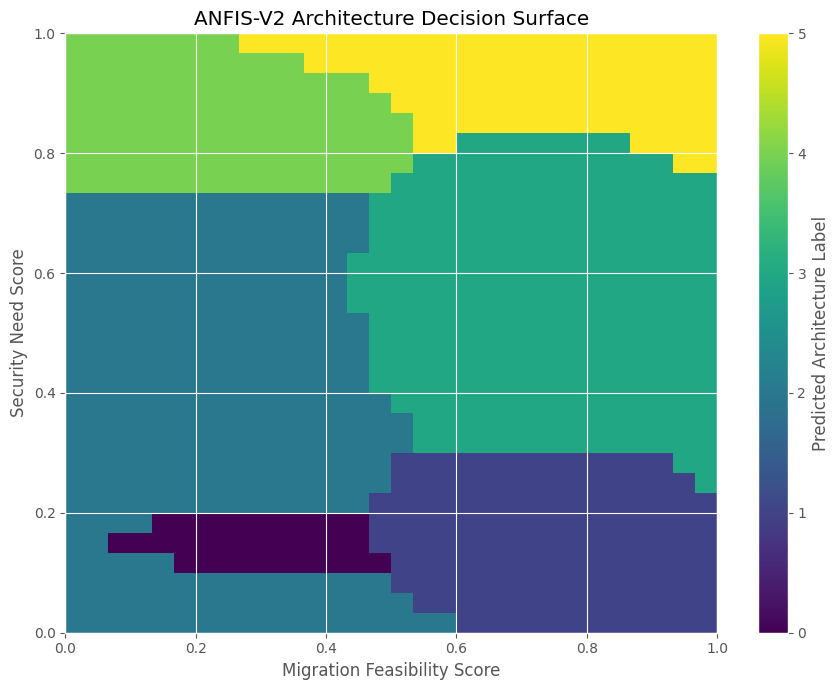

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
model_v2.eval()
security_idx = features.index("Security_Need_Score")
feasibility_idx = features.index("Migration_Feasibility_Score")
security_values = np.linspace(0,1,30)
feasibility_values = np.linspace(0,1,30)
base_input = X_test_scaled.mean(axis=0)
decision_grid = np.zeros((len(security_values),len(feasibility_values)))

for i,s in enumerate(security_values):
    for j,f in enumerate(feasibility_values):
        sample = base_input.copy()
        sample[security_idx] = s
        sample[feasibility_idx] = f

        sample_tensor = torch.tensor(sample,dtype=torch.float32).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model_v2(sample_tensor)
            prediction = torch.argmax(output,dim=1).item()

        decision_grid[i,j] = prediction

plt.figure(figsize=(9,7))
plt.imshow(decision_grid,origin="lower",aspect="auto",extent=[0,1,0,1])
plt.xlabel("Migration Feasibility Score")
plt.ylabel("Security Need Score")
plt.title("ANFIS-V2 Architecture Decision Surface")
plt.colorbar(label="Predicted Architecture Label")
plt.tight_layout()
plt.show()

In [101]:
unique_predictions = np.unique(decision_grid.astype(int))
print("Architecture labels activated:",unique_predictions)
for label in unique_predictions:
    percentage = np.mean(decision_grid == label) * 100
    print(f"Architecture {int(label)}: {percentage:.2f}% of decision surface")

Architecture labels activated: [0 1 2 3 4 5]
Architecture 0: 3.56% of decision surface
Architecture 1: 14.56% of decision surface
Architecture 2: 32.00% of decision surface
Architecture 3: 27.11% of decision surface
Architecture 4: 12.33% of decision surface
Architecture 5: 10.44% of decision surface


In [102]:
test_cases = [
    ("Low Security / Low Feasibility",0.20,0.20),
    ("Low Security / High Feasibility",0.20,0.80),
    ("Medium Security / Medium Feasibility",0.50,0.50),
    ("High Security / Low Feasibility",0.80,0.20),
    ("High Security / High Feasibility",0.80,0.80)]
for name,s,f in test_cases:
    sample = base_input.copy()
    sample[security_idx] = s
    sample[feasibility_idx] = f

    sample_tensor = torch.tensor(sample,dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model_v2(sample_tensor)
        prediction = torch.argmax(output,dim=1).item()
        probabilities = torch.softmax(output,dim=1).cpu().numpy()[0]

    print(f"\n{name}")
    print(f"Security Need       : {s:.2f}")
    print(f"Migration Feasibility: {f:.2f}")
    print(f"Predicted Architecture Label: {prediction}")
    print(f"Confidence: {probabilities[prediction]:.4f}")


Low Security / Low Feasibility
Security Need       : 0.20
Migration Feasibility: 0.20
Predicted Architecture Label: 2
Confidence: 0.7013

Low Security / High Feasibility
Security Need       : 0.20
Migration Feasibility: 0.80
Predicted Architecture Label: 1
Confidence: 0.9761

Medium Security / Medium Feasibility
Security Need       : 0.50
Migration Feasibility: 0.50
Predicted Architecture Label: 3
Confidence: 0.9841

High Security / Low Feasibility
Security Need       : 0.80
Migration Feasibility: 0.20
Predicted Architecture Label: 4
Confidence: 0.9783

High Security / High Feasibility
Security Need       : 0.80
Migration Feasibility: 0.80
Predicted Architecture Label: 3
Confidence: 0.9854


FINAL RECOMMENDATION ARCHITECTURE

In [103]:
for name,value in globals().copy().items():
    if isinstance(value,dict) and len(value) <= 10:
        print(name,"=",value)

data = {'Asset': ['Medical Records', 'Customer Database', 'Payment Gateway', 'Certificate Authority', 'Identity Management', 'Financial Ledger', 'Research Repository', 'Cloud Storage', 'VPN Server', 'Email Server', 'IoT Gateway', 'Power Grid Controller', 'Government Records', 'Satellite Communication', 'Payroll System', 'Supply Chain Database', 'Blockchain Node', 'Hospital Imaging System', 'Insurance Database', 'Bank Transaction Server', 'HR Records', 'Smart Meter Network', 'Manufacturing Control', 'Telemedicine Server', 'Digital Identity Vault', 'Tax Records', 'University Research Data', 'Defense Communication', 'Air Traffic Control', 'Critical Infrastructure'], 'Sensitivity': [5, 5, 5, 5, 4, 5, 4, 3, 4, 2, 3, 5, 5, 5, 3, 4, 5, 5, 4, 5, 3, 2, 4, 5, 5, 4, 5, 5, 5, 5], 'Confidentiality_Lifetime': [5, 5, 5, 5, 4, 5, 4, 3, 4, 2, 3, 5, 5, 5, 3, 4, 4, 5, 4, 5, 2, 2, 3, 5, 5, 4, 5, 5, 5, 5], 'Future_Quantum_Risk': [5, 5, 5, 4, 4, 5, 4, 3, 3, 1, 2, 5, 5, 5, 3, 4, 4, 5, 4, 5, 2, 2, 3, 5, 5, 4,

In [104]:
architecture_map = {
    'Hybrid TLS': 0,
    'ML-KEM': 1,
    'ML-DSA + ML-KEM': 2,
    'ML-DSA + ML-KEM + ZKP': 3,
    'ML-DSA + ML-KEM + QKD': 4,
    'ML-DSA + ML-KEM + QKD + ZKP': 5
}

architecture_names = {v:k for k,v in architecture_map.items()}

model_v2.eval()

X_full_scaled = scaler.transform(X).astype(np.float32)
X_full_tensor = torch.tensor(X_full_scaled,dtype=torch.float32).to(device)

with torch.no_grad():
    outputs = model_v2(X_full_tensor)
    predictions = torch.argmax(outputs,dim=1).cpu().numpy()
    probabilities = torch.softmax(outputs,dim=1).cpu().numpy()

final_results = pd.DataFrame({
    "Predicted_Label": predictions,
    "Confidence": probabilities.max(axis=1)
})

final_results["Recommended_Architecture"] = final_results["Predicted_Label"].map(architecture_names)

display(final_results.head(20))

,Predicted_Label,Confidence,Recommended_Architecture
0,3,0.986024,ML-DSA + ML-KEM + ZKP
1,4,0.979552,ML-DSA + ML-KEM + QKD
2,3,0.987798,ML-DSA + ML-KEM + ZKP
3,3,0.987761,ML-DSA + ML-KEM + ZKP
4,4,0.979659,ML-DSA + ML-KEM + QKD
5,2,0.987188,ML-DSA + ML-KEM
6,2,0.990015,ML-DSA + ML-KEM
7,3,0.982100,ML-DSA + ML-KEM + ZKP
8,2,0.990538,ML-DSA + ML-KEM
9,2,0.989263,ML-DSA + ML-KEM


In [105]:
architecture_names = {
    0: "Hybrid TLS",
    1: "ML-KEM",
    2: "ML-DSA + ML-KEM",
    3: "ML-DSA + ML-KEM + ZKP",
    4: "ML-DSA + ML-KEM + QKD",
    5: "ML-DSA + ML-KEM + QKD + ZKP"
}

In [106]:
final_results["Recommended_Architecture"] = final_results["Predicted_Label"].map(architecture_names)
display(final_results)

,Predicted_Label,Confidence,Recommended_Architecture
0,3,0.986024,ML-DSA + ML-KEM + ZKP
1,4,0.979552,ML-DSA + ML-KEM + QKD
2,3,0.987798,ML-DSA + ML-KEM + ZKP
3,3,0.987761,ML-DSA + ML-KEM + ZKP
4,4,0.979659,ML-DSA + ML-KEM + QKD
...,...,...,...
495,2,0.980157,ML-DSA + ML-KEM
496,3,0.987798,ML-DSA + ML-KEM + ZKP
497,2,0.989584,ML-DSA + ML-KEM
498,3,0.987568,ML-DSA + ML-KEM + ZKP


In [107]:
architecture_names = {
    0: "Hybrid TLS",
    1: "ML-KEM",
    2: "ML-DSA + ML-KEM",
    3: "ML-DSA + ML-KEM + ZKP",
    4: "ML-DSA + ML-KEM + QKD",
    5: "ML-DSA + ML-KEM + QKD + ZKP"
}

final_results = pd.DataFrame({
    "Predicted_Label": predictions,
    "Confidence": probabilities.max(axis=1)
})

final_results["Recommended_Architecture"] = final_results["Predicted_Label"].map(architecture_names)

print("Label mapping check:")
for label,name in architecture_names.items():
    print(f"{label} -> {name}")

print("\nPrediction distribution:")
print(final_results["Predicted_Label"].value_counts().sort_index())

display(final_results.head(20))

Label mapping check:
0 -> Hybrid TLS
1 -> ML-KEM
2 -> ML-DSA + ML-KEM
3 -> ML-DSA + ML-KEM + ZKP
4 -> ML-DSA + ML-KEM + QKD
5 -> ML-DSA + ML-KEM + QKD + ZKP

Prediction distribution:
Predicted_Label
0     28
1     43
2    187
3    196
4     27
5     19
Name: count, dtype: int64


,Predicted_Label,Confidence,Recommended_Architecture
0,3,0.986024,ML-DSA + ML-KEM + ZKP
1,4,0.979552,ML-DSA + ML-KEM + QKD
2,3,0.987798,ML-DSA + ML-KEM + ZKP
3,3,0.987761,ML-DSA + ML-KEM + ZKP
4,4,0.979659,ML-DSA + ML-KEM + QKD
5,2,0.987188,ML-DSA + ML-KEM
6,2,0.990015,ML-DSA + ML-KEM
7,3,0.982100,ML-DSA + ML-KEM + ZKP
8,2,0.990538,ML-DSA + ML-KEM
9,2,0.989263,ML-DSA + ML-KEM


In [108]:
label_to_architecture = {
    0: "Hybrid TLS",
    1: "ML-KEM",
    2: "ML-DSA + ML-KEM",
    3: "ML-DSA + ML-KEM + ZKP",
    4: "ML-DSA + ML-KEM + QKD",
    5: "ML-DSA + ML-KEM + QKD + ZKP"
}

final_results = pd.DataFrame({
    "Predicted_Label": predictions,
    "Confidence": probabilities.max(axis=1)
})

final_results["Recommended_Architecture"] = [
    label_to_architecture[int(label)]
    for label in final_results["Predicted_Label"]
]

print("Mapping verification:")
for label in sorted(label_to_architecture):
    print(f"Label {label} -> {label_to_architecture[label]}")

display(final_results.head(20))

Mapping verification:
Label 0 -> Hybrid TLS
Label 1 -> ML-KEM
Label 2 -> ML-DSA + ML-KEM
Label 3 -> ML-DSA + ML-KEM + ZKP
Label 4 -> ML-DSA + ML-KEM + QKD
Label 5 -> ML-DSA + ML-KEM + QKD + ZKP


,Predicted_Label,Confidence,Recommended_Architecture
0,3,0.986024,ML-DSA + ML-KEM + ZKP
1,4,0.979552,ML-DSA + ML-KEM + QKD
2,3,0.987798,ML-DSA + ML-KEM + ZKP
3,3,0.987761,ML-DSA + ML-KEM + ZKP
4,4,0.979659,ML-DSA + ML-KEM + QKD
5,2,0.987188,ML-DSA + ML-KEM
6,2,0.990015,ML-DSA + ML-KEM
7,3,0.982100,ML-DSA + ML-KEM + ZKP
8,2,0.990538,ML-DSA + ML-KEM
9,2,0.989263,ML-DSA + ML-KEM


In [109]:
print("CURRENT MAPPING:")
print(label_to_architecture)

print("\nCURRENT PREDICTIONS:")
print(predictions[:10])

print("\nDIRECT TEST:")
for x in range(6):
    print(x,"->",label_to_architecture[x])

CURRENT MAPPING:
{0: 'Hybrid TLS', 1: 'ML-KEM', 2: 'ML-DSA + ML-KEM', 3: 'ML-DSA + ML-KEM + ZKP', 4: 'ML-DSA + ML-KEM + QKD', 5: 'ML-DSA + ML-KEM + QKD + ZKP'}

CURRENT PREDICTIONS:
[3 4 3 3 4 2 2 3 2 2]

DIRECT TEST:
0 -> Hybrid TLS
1 -> ML-KEM
2 -> ML-DSA + ML-KEM
3 -> ML-DSA + ML-KEM + ZKP
4 -> ML-DSA + ML-KEM + QKD
5 -> ML-DSA + ML-KEM + QKD + ZKP


In [110]:
recommendation_summary = (
    final_results["Recommended_Architecture"]
    .value_counts()
    .rename_axis("Recommended_Architecture")
    .reset_index(name="Count")
)

recommendation_summary["Percentage"] = (
    recommendation_summary["Count"] / len(final_results) * 100
).round(2)

display(recommendation_summary)

,Recommended_Architecture,Count,Percentage
0,ML-DSA + ML-KEM + ZKP,196,39.2
1,ML-DSA + ML-KEM,187,37.4
2,ML-KEM,43,8.6
3,Hybrid TLS,28,5.6
4,ML-DSA + ML-KEM + QKD,27,5.4
5,ML-DSA + ML-KEM + QKD + ZKP,19,3.8


In [111]:
real_assets = pd.DataFrame(data).copy()
real_assets["Authentication_Requirement"] = real_assets["Authentication"].map({0:1,1:5})
real_assets["Privacy_Requirement"] = real_assets["Privacy"].map({0:1,1:5})
real_assets["Integrity_Requirement"] = real_assets["Integrity"].map({0:1,1:5})
real_assets["Regulatory_Compliance"] = 3
real_assets["Scalability_Requirement"] = 3
real_assets["Security_Need_Score"] = (
    0.20*real_assets["Sensitivity"]
    + 0.15*real_assets["Confidentiality_Lifetime"]
    + 0.15*real_assets["Future_Quantum_Risk"]
    + 0.15*real_assets["Authentication_Requirement"]
    + 0.10*real_assets["Privacy_Requirement"]
    + 0.10*real_assets["Integrity_Requirement"]
    + 0.10*real_assets["Regulatory_Compliance"]
    + 0.05*real_assets["Scalability_Requirement"]
)
real_assets["Migration_Feasibility_Score"] = (
    0.60*real_assets["Infrastructure_Readiness"]
    + 0.40*(6-real_assets["Migration_Cost"])
)
X_real = real_assets[features].copy()

print("Real asset feature shape:",X_real.shape)
print("Expected feature count:",len(features))
print("\nFeature check:")
print(X_real.columns.tolist())

X_real_scaled = scaler.transform(X_real).astype(np.float32)

X_real_tensor = torch.tensor(
    X_real_scaled,
    dtype=torch.float32
).to(device)
model_v2.eval()

with torch.no_grad():
    real_outputs = model_v2(X_real_tensor)
    real_predictions = torch.argmax(
        real_outputs,dim=1
    ).cpu().numpy()

    real_probabilities = torch.softmax(
        real_outputs,dim=1
    ).cpu().numpy()

label_to_architecture = {
    0:"Hybrid TLS",
    1:"ML-KEM",
    2:"ML-DSA + ML-KEM",
    3:"ML-DSA + ML-KEM + ZKP",
    4:"ML-DSA + ML-KEM + QKD",
    5:"ML-DSA + ML-KEM + QKD + ZKP"
}

real_results = pd.DataFrame({
    "Asset":real_assets["Asset"],
    "Security_Need":real_assets["Security_Need_Score"].round(2),
    "Migration_Feasibility":real_assets["Migration_Feasibility_Score"].round(2),
    "Predicted_Label":real_predictions,
    "Confidence":real_probabilities.max(axis=1).round(3)
})

real_results["Recommended_Architecture"] = [
    label_to_architecture[int(x)]
    for x in real_results["Predicted_Label"]
]

print("\n=============================================")
print("      ANFIS-V2 REAL ASSET RESULTS")
print("=============================================")

display(real_results)

Real asset feature shape: (30, 12)
Expected feature count: 12

Feature check:
['Sensitivity', 'Confidentiality_Lifetime', 'Future_Quantum_Risk', 'Infrastructure_Readiness', 'Migration_Cost', 'Authentication_Requirement', 'Privacy_Requirement', 'Integrity_Requirement', 'Regulatory_Compliance', 'Scalability_Requirement', 'Security_Need_Score', 'Migration_Feasibility_Score']

      ANFIS-V2 REAL ASSET RESULTS


,Asset,Security_Need,Migration_Feasibility,Predicted_Label,Confidence,Recommended_Architecture
0,Medical Records,4.70,2.6,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
1,Customer Database,4.70,2.6,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
2,Payment Gateway,4.30,2.8,4,0.980,ML-DSA + ML-KEM + QKD
3,Certificate Authority,4.15,1.6,4,0.980,ML-DSA + ML-KEM + QKD
4,Identity Management,3.80,2.6,4,0.979,ML-DSA + ML-KEM + QKD
5,Financial Ledger,4.70,2.8,5,0.963,ML-DSA + ML-KEM + QKD + ZKP
6,Research Repository,4.20,2.6,4,0.980,ML-DSA + ML-KEM + QKD
7,Cloud Storage,3.30,4.2,3,0.988,ML-DSA + ML-KEM + ZKP
8,VPN Server,3.65,3.6,3,0.988,ML-DSA + ML-KEM + ZKP
9,Email Server,2.65,4.6,3,0.988,ML-DSA + ML-KEM + ZKP


In [112]:
real_architecture_summary = (
    real_results["Recommended_Architecture"]
    .value_counts()
    .rename_axis("Recommended_Architecture")
    .reset_index(name="Asset_Count")
)

real_architecture_summary["Percentage"] = (
    real_architecture_summary["Asset_Count"] /
    len(real_results) * 100
).round(2)

display(real_architecture_summary)

,Recommended_Architecture,Asset_Count,Percentage
0,ML-DSA + ML-KEM + QKD,16,53.33
1,ML-DSA + ML-KEM + ZKP,7,23.33
2,ML-DSA + ML-KEM + QKD + ZKP,6,20.00
3,ML-DSA + ML-KEM,1,3.33


In [113]:
print("Mean confidence :",round(real_results["Confidence"].mean(),4))
print("Minimum confidence:",round(real_results["Confidence"].min(),4))
print("Maximum confidence:",round(real_results["Confidence"].max(),4))

print("\nLowest-confidence assets:")
display(
    real_results[
        ["Asset","Predicted_Label","Confidence","Recommended_Architecture"]
    ]
    .sort_values("Confidence")
    .head(5)
)

Mean confidence : 0.9334
Minimum confidence: 0.529
Maximum confidence: 0.988

Lowest-confidence assets:


,Asset,Predicted_Label,Confidence,Recommended_Architecture
15,Supply Chain Database,4,0.529,ML-DSA + ML-KEM + QKD
0,Medical Records,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
1,Customer Database,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
17,Hospital Imaging System,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
23,Telemedicine Server,5,0.749,ML-DSA + ML-KEM + QKD + ZKP
